---
title: "Where the axial dispersion coefficient comes from: Edwards & Richardson's packed bed"
description: "A pulse of argon in air, two response curves, and the two-point moment method that turns them into D_L, reproduced in pymrm, against the points digitised from their Figure 9."
categories: [sec:A, struct:S4, tier:T1, data:tier2, phase:gas]
date: 2026-08-02
---

# Where the axial dispersion coefficient comes from

**Catalog ID:** `A2.5` · **Structures:** `S4` (1-D transient advection-dispersion) ·
**Tier:** T1

[`A2.1`](../A2.1-danckwerts-boundary-conditions/) takes the axial-dispersion
reactor as given and asks what its boundary conditions mean.
[`A2.3`](../A2.3-taylor-aris-dispersion/) derives a dispersion coefficient for a
tube from first principles. This page is about the third question, the
experimental one: **for a real packed bed, where does the number come from, and
how good is it?**

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01.4"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A2.5-edwards-richardson-dispersion"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import least_squares
from pymrm import vanleer
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (TracerBed, simulate_experiment, simulate_two_zone,  # this page's model.py
                   moments, invert_two_point, emg, D_two_zone, channelling_case,
                   two_zone_split, peak_time, STEP_LOG, X0, X1, SIGMA, TAIL)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
SEED = 20260802                # every resampling below seeds from this, explicitly


# Deviations are reported ONE way everywhere on this page:
#     dev = (model - measured) / measured
def dev(model, measured):
    return np.asarray(model, float) / np.asarray(measured, float) - 1.0

## Background

Edwards and Richardson pushed air through beds of glass ballotini, sand and
powdered perspex, injected a pulse of argon, and watched it come out on a
$\beta$-ray ionisation detector. They did this over a wider Reynolds-number
range than anyone before them (the range they print is listed under
*Parameters and assumptions*) and produced the correlation that is still quoted
for gas-phase axial dispersion in packed beds.

Three things make this a page rather than a curve fit.

**The measurement is an inverse problem, and its forward model is the thing the
gallery already builds.** A dispersion coefficient is never observed. What is
observed is a concentration against time at two positions; $D_L$ is whatever
value of the parameter in

$$\frac{\partial c}{\partial t} + u\frac{\partial c}{\partial x}
  = D_L\frac{\partial^2 c}{\partial x^2}$$

makes the second curve follow from the first. So a page that can solve that
equation can *simulate the whole experiment*, invert it with the authors' own
formulae, and check that the number it gets back is the number it put in. That
check has real power, because the discretisation adds dispersion of its own and
the inversion cannot tell it apart from the physical kind.

**The correlation has structure, not just constants.** It is a molecular
diffusion floor plus an eddy-diffusion term, and each has a limit the model must
hit: at low Reynolds number $D_L$ must approach the molecular diffusivity times
a tortuosity factor, and at high Reynolds number the Péclet number must approach
2. In between, the data show a *maximum* in Péclet number that the sum of those
two mechanisms cannot produce at all, and that is what the paper's third term
is for.

**They also found where their own model fails.** With their finest particles the
moment analysis returned dispersion coefficients far above the correlation, and
the response curve computed from the fitted $D_L$ peaked *later* than the one
they measured. They attributed it to channelling. That diagnostic, the shape
disagreeing while the moments agree by construction, is reproduced in the last
part of the results.

## The published model

### The measurement

For a pulse in an infinite uniform bed, Aris showed that two response curves
measured a distance $\Delta x$ apart are related by three exact statements,
which are Edwards & Richardson's Eqs. (5), (6) and (7):

$$A_1 = A_2, \qquad
\Delta\bar t = \bar t_2 - \bar t_1 = \frac{\Delta x}{u}, \qquad
\Delta\sigma^2 = \sigma_2^2 - \sigma_1^2 = \frac{2 D_L \Delta x}{u^3},$$

with area, mean and variance defined by their Eqs. (2) to (4),

$$A=\int_0^\infty c\,\mathrm dt,\qquad
\bar t=\frac1A\int_0^\infty c\,t\,\mathrm dt,\qquad
\sigma^2=\frac1A\int_0^\infty c\,t^2\,\mathrm dt-\bar t^{\,2}.$$

Everything that happens *before* the first detector (the shape of the injected
pulse, the distributor, the entrance section) cancels in the differences. That
is the whole point of measuring twice, and it is why the method needs no
knowledge of the input.

The three relations are exact for the equation above, not approximations. In
Laplace space the downstream transfer function is $\exp(\lambda\Delta x)$ with
$\lambda = \bigl(u-\sqrt{u^2+4D_Ls}\bigr)/2D_L = -s/u + D_Ls^2/u^3 + O(s^3)$,
and the first three coefficients of that expansion are exactly the three
statements above.

### The correlation

Two mechanisms, taken as additive (their Eqs. 13 to 15):

$$D_L = \gamma D_M + \tfrac12 u d_p .$$

The first term is molecular diffusion reduced by the tortuosity of the bed; the
second is the mixing-cell and turbulent-mixing limit $\mathrm{Pe} = u d_p/D_L =
2$ of Aris & Amundson and of Prausnitz. This form rises monotonically to
$\mathrm{Pe}=2$ and can never exceed it, but the measurements do. Radial mixing
inside the bed reduces axial spreading, and E&R put that in as an empirical
correction factor on the eddy term (their Eq. 16):

$$D_L = \gamma D_M + \frac{\tfrac12 u d_p}{1 + \beta D_M/(u d_p)} .$$

With $\gamma$ measured and $\beta$ fitted this is their Eq. (17), quoted in the
abstract as the result of the paper, and divided through by $u d_p$ with the
voidage $\varepsilon$ and Schmidt number $\mathrm{Sc}$ they state, their Eq. (18):

$$\mathrm{Pe}^{-1} = \frac{a}{\mathrm{Re}} + \frac{\tfrac12}{1+b/\mathrm{Re}},
\qquad a = \frac{\gamma\varepsilon}{\mathrm{Sc}},\quad
b = \frac{\beta\varepsilon}{\mathrm{Sc}} .$$

The constants as printed are listed in the next cell, read from the dataset.

**Definitions matter here.** $u$ is the *interstitial* velocity throughout, so
$\mathrm{Re} = u d_p \varepsilon/\nu$ is built on the superficial velocity
$u\varepsilon$ while $\mathrm{Pe} = u d_p / D_L$ is not. Mixing the two is the
easiest way to be wrong by a factor $1/\varepsilon$.

## Parameters and assumptions

**The system is one gas pair only.** Argon traced into air. The paper says
plainly that "only one system (argon-air) has been studied and thus the effect
of variations in the kinematic viscosity term $\nu$ in the Reynolds number has
not been established". Nothing on this page tests it either.

**Assumptions carried into every calculation below.** One-dimensional flow with
no radial concentration gradient (the paper's porous distributor is what buys
this); constant $u$ and constant $D_L$; a non-porous, non-adsorbing solid, so no
intraparticle hold-up; and an infinite bed, in the sense that the pulse never
reaches either end while it is being observed.

**$\nu$ is not printed, but it is implied.** The paper gives $\mathrm{Sc}$ and
$D_M$, so $\nu = \mathrm{Sc}\,D_M$. Every velocity below comes from that. It is
a reconstruction from two printed numbers, not an outside value.

**Two runs are worked in detail**, both taken from figure legends: the
large-particle check of Figure 13 and the fine-particle failure of Figure 15.
**Figure 15's legend prints no detector separation**, and the paper's test
section was one of two tubes. Where the Figure-15 reconstruction needs a
$\Delta x$ it assumes the one Figure 13 prints; the section that uses it says
so and reports the alternative beside it. Nothing else on the page depends on
the choice. The cell below prints every one of these numbers from the dataset.

In [3]:
stated = load_data("edwards-richardson-1968-stated.csv", page=PAGE)
tab1 = load_data("edwards-richardson-1968-table1.csv", page=PAGE)
P = dict(zip(stated.quantity, stated.value))          # printed values, by name

gamma = P["tortuosity_factor_gamma"]          # Eq. (17), p. 119
beta = P["correction_constant_beta"]          # Eq. (17), p. 119
D_M = P["molecular_diffusivity_argon_air"]    # cm2/s, p. 117
eps18 = P["voidage_used_in_eq18"]             # voidage used for Eq. (18), p. 119
Sc18 = P["schmidt_number_used_in_eq18"]       # Schmidt number used for Eq. (18), p. 119
nu_air = Sc18 * D_M                           # cm2/s, reconstructed: nu = Sc D_M
C_EDDY = P["eq18_eddy_coefficient"]           # eddy coefficient, from Pe -> 2
A_printed = P["eq18_molecular_coefficient"]   # Eq. (18) as printed, p. 119
B_printed = P["eq18_correction_coefficient"]

DP13, RE13, DX13 = (P["fig13_particle_diameter"], P["fig13_reynolds"],
                    P["fig13_separation"])        # Figure 13 legend, p. 119
DP15, RE15, DL15 = (P["fig15_particle_diameter"], P["fig15_reynolds"],
                    P["fig15_apparent_dispersion_coefficient"])   # Figure 15, p. 120
DX_SHORT, DX_LONG = P["bed_length_min"], P["bed_length_max"]      # conclusions, p. 120

display(Markdown(rf"""
**As printed.** Eq. (17): $D_L = {gamma}\,D_M + 0.5\,u d_p/(1 + {beta}\,D_M/(u d_p))$, valid for
${P['reynolds_min']} < \mathrm{{Re}} < {P['reynolds_max']:g}$ and
${P['particle_diameter_min']} < d_p < {P['particle_diameter_max']}$ cm.
Eq. (18): $\mathrm{{Pe}}^{{-1}} = {A_printed}\,\mathrm{{Re}}^{{-1}} + {C_EDDY}/(1 + {B_printed}\,\mathrm{{Re}}^{{-1}})$,
with $\varepsilon$ = {eps18} and Sc = {Sc18}.

| quantity | value | source |
|---|---|---|
| $D_M$, argon in air | {D_M} cm²/s | p. 117 |
| $\nu = \mathrm{{Sc}}\,D_M$ | {nu_air:.4f} cm²/s | reconstructed |
| Figure 13 run | Re = {RE13}, $d_p$ = {DP13} cm, $\Delta x$ = {DX13:g} cm | legend, p. 119 |
| Figure 15 run | $d_p$ = {DP15} cm, Re = {RE15}, apparent $D_L$ = {DL15} cm²/s | legend, p. 120 |
| test sections | {DX_SHORT} cm and {DX_LONG - DX_SHORT:g} cm long, so separations from {DX_SHORT} to {DX_LONG} cm | pp. 111, 120 |
"""))


**As printed.** Eq. (17): $D_L = 0.73\,D_M + 0.5\,u d_p/(1 + 9.7\,D_M/(u d_p))$, valid for
$0.008 < \mathrm{Re} < 50$ and
$0.0377 < d_p < 0.6$ cm.
Eq. (18): $\mathrm{Pe}^{-1} = 0.38\,\mathrm{Re}^{-1} + 0.5/(1 + 5.0\,\mathrm{Re}^{-1})$,
with $\varepsilon$ = 0.37 and Sc = 0.72.

| quantity | value | source |
|---|---|---|
| $D_M$, argon in air | 0.205 cm²/s | p. 117 |
| $\nu = \mathrm{Sc}\,D_M$ | 0.1476 cm²/s | reconstructed |
| Figure 13 run | Re = 24.6, $d_p$ = 0.3 cm, $\Delta x$ = 100 cm | legend, p. 119 |
| Figure 15 run | $d_p$ = 0.0097 cm, Re = 0.071, apparent $D_L$ = 0.503 cm²/s | legend, p. 120 |
| test sections | 21.3 cm and 100 cm long, so separations from 21.3 to 121.3 cm | pp. 111, 120 |


## The data

Three files, of two very different kinds.

**Printed numbers.** The constants, ranges and worked-run conditions, and
Table 1's particle properties. These were read off 600 dpi page renders because
the text layer of this 1968 Pergamon scan drops the mid-dot decimal separator
(it renders the largest bead size as `0607` and the finest as `o%l97`). Nothing
was repaired by inference.

**Digitised measurements.** Edwards & Richardson print no table of dispersion
coefficients; the measurements exist only as Figures 7 to 9 and 14. Figure 9,
the Péclet-Reynolds plot for the five large bead sizes, was digitised (marker
positions only), which is what makes this page tier 2 rather than tier 6. The
count and the Reynolds range come out of the file below, not out of this
sentence.

Two things made that digitisation cheap and safe. The dashed curve drawn through
the points *is* Eq. (18), whose constants are printed, so its pixel path could be
computed rather than traced and then erased before marker detection; that the
computed path lands on the printed dashes over the whole figure is itself a
check on both the axis calibration and the transcription. And Eq. (18) contains
no particle-size term, so the five marker shapes carry no information this test
needs: only positions were extracted and **no row carries a series label**.

**Where the extraction needed help, and where it failed.** In four places the
glyphs overlap by more than half their width, and there the ink centroid of the
blob belongs to more than one marker. Those clusters were redone as units: every
row inside them discarded, and one centre per glyph put back at the best-fit
position of that glyph's *own* template, seeded by a visual audit of the 600 dpi
render. One of the discarded rows sat on a bare stretch of the dashed curve, and
one marker that had carried no row at all was added. The sidecar carries the
boxes, the old rows and the new centres, and the cell below counts them. Some
glyphs are still fused into their neighbours badly enough that no centre can be
fixed for them; they are listed in the sidecar and printed below, with what
including the most nearly resolvable of them would do to the headline.

In [4]:
fig9 = load_data("edwards-richardson-1968-fig9.csv", page=PAGE)
meta9 = load_meta("edwards-richardson-1968-fig9.csv", page=PAGE)
print(cite_data(meta9))
print(f"\nFigure 9: {len(fig9)} markers, "
      f"Re {fig9.reynolds.min():.5f} to {fig9.reynolds.max():.3g}, "
      f"Pe {fig9.peclet.min():.4f} to {fig9.peclet.max():.3f}")
print(f"the paper's own stated range: Re {P['reynolds_min']} to {P['reynolds_max']:g}"
      "  (never used in the axis calibration)")

# The audit of the merged clusters, counted from the sidecar rather than retyped.
clusters = meta9["corrected"]["clusters"]
n_old_rows = sum(len(c["old_rows"]) for c in clusters)
n_new_rows = sum(len(c["new_centres"]) for c in clusters)
moved_px = np.concatenate([c["moved_px"] for c in clusters])
MOVED_PX = 5.0                     # the ink-centroid systematic of the sidecar, px
big_moves = moved_px[moved_px >= MOVED_PX]
print(f"\nmerged-cluster audit: {len(clusters)} clusters, {n_old_rows} rows replaced by"
      f" {n_new_rows} re-fitted centres; {len(big_moves)} of the {len(moved_px)} replaced"
      f" rows moved by {MOVED_PX:g} px or more ({big_moves.min():.1f} to"
      f" {big_moves.max():.1f} px)")

# What the extraction could NOT do, read from the sidecar rather than retyped.
gone = meta9["missing"]["unrecovered_markers"]
print(f"\n{len(gone)} glyphs are fused into a neighbour and carry no row in the file,"
      " at approximately")
for m in gone:
    print(f"   Re {m['reynolds']:6.2f}  Pe {m['peclet']:5.2f}"
          f"   ({m['leftover_ink_px']} px of unexplained ink at"
          f" ({m['pixel_x']}, {m['pixel_y']}))")
print(f"   -> {meta9['missing']['effect_if_included']}")

print("\nTable 1, the sizes Figures 7 and 9 cover:")
big = tab1[tab1.d_p_cm >= P["particle_diameter_min"]]
print(big[["material", "d_p_cm", "voidage", "material_density_g_cm3",
           "bulk_density_g_cm3"]].to_string(index=False))


# A check Table 1 pays for: 1 - bulk/material density must be the printed voidage.
# It tests three transcribed columns against each other on every row.
def voidage_residuals(voidage):
    return (1.0 - tab1.bulk_density_g_cm3 / tab1.material_density_g_cm3 - voidage).abs()


resid_void = voidage_residuals(tab1.voidage)
print(f"\nvoidage against 1 - bulk/material density, all {len(tab1)} rows:"
      f" worst absolute residual {resid_void.max():.4f}"
      f" (on d_p = {tab1.d_p_cm[resid_void.idxmax()]} cm),"
      f" mean {resid_void.mean():.4f}")

print("\nprinted constants used below:")
for k in ("tortuosity_factor_gamma", "correction_constant_beta",
          "molecular_diffusivity_argon_air", "voidage_used_in_eq18",
          "schmidt_number_used_in_eq18", "dispersion_coefficient_low_Re"):
    row = stated[stated.quantity == k].iloc[0]
    print(f"  {k:38s} {row.value:>9g} {row.unit:8s} (p. {row.page})")

Edwards, M. F.; Richardson, J. F. (1968) — Chemical Engineering Science 23(2) 109-123 — doi:10.1016/0009-2509(68)87056-3 — digitised from Figure 9, journal page 116

Figure 9: 55 markers, Re 0.00857 to 49.1, Pe 0.0228 to 4.158
the paper's own stated range: Re 0.008 to 50  (never used in the axis calibration)

merged-cluster audit: 4 clusters, 10 rows replaced by 11 re-fitted centres; 7 of the 10 replaced rows moved by 5 px or more (9.5 to 26.5 px)

3 glyphs are fused into a neighbour and carry no row in the file, at approximately
   Re   0.82  Pe  2.08   (171 px of unexplained ink at (1394.1, 337.7))
   Re   1.79  Pe  2.67   (309 px of unexplained ink at (1596.5, 272.3))
   Re   2.49  Pe  3.62   (275 px of unexplained ink at (1681.7, 192.3))
   -> adding that circle - a ring fit at (1592.0, 263.0), which the calibration puts at Re = 1.76, Pe = 2.77 - would move the mean absolute deviation from 11.75 % to 11.62 %, the bias from +0.003 % to +0.08 %, and the count above Pe = 2 from 30 to 

### Five checks the paper pays for, before any modelling

A page-image transcription is a transcription and needs checking like any other
(the `B3.1` lesson). This paper hands over five ways to do it, none of which
needs the figure or a solver, and each of which can fail on a single mis-read
digit. The defect table in the validation injects exactly such digits and shows
the numbers move. One of the five does *not* come out, and it is reported as it
stands.

In [5]:
def D_L_eq17(u, dp, D_M=D_M, gamma=gamma, beta=beta):
    """E&R Eq. (17): molecular floor plus corrected eddy term. u is INTERSTITIAL."""
    return gamma * D_M + 0.5 * u * dp / (1.0 + beta * D_M / (u * dp))


def Pe_eq18(Re, A=A_printed, B=B_printed, C=C_EDDY):
    """E&R Eq. (18): Pe^-1 = A/Re + C/(1 + B/Re)."""
    return 1.0 / (A / Re + C / (1.0 + B / Re))


def Pe_max_eq18(A=A_printed, B=B_printed, C=C_EDDY):
    """Where d(Pe^-1)/dRe vanishes: C B/(Re+B)^2 = A/Re^2, in closed form."""
    r = np.sqrt(A / (C * B))
    Re_s = r * B / (1.0 - r)
    return Re_s, Pe_eq18(Re_s, A=A, B=B, C=C)


def eq18_from_eq17(g=gamma, b=beta, eps=eps18, Sc=Sc18):
    """D_M/(u d_p) = (nu/Sc)/(Re nu/eps) = eps/(Sc Re): Eq. (18)'s coefficients."""
    return g * eps / Sc, b * eps / Sc


k18 = eps18 / Sc18
A_derived, B_derived = eq18_from_eq17()

# --- 1. gamma is the low-Re plateau over D_M ----------------------------------
gamma_ratio = P["dispersion_coefficient_low_Re"] / D_M
gamma_ci = P["dispersion_coefficient_low_Re_ci95"] / D_M
# --- 3. where Eq. (18)'s voidage comes from -------------------------------------
eps_mean = float(big.voidage.mean())
# --- 4. the maximum of Eq. (18), which the paper only bounds --------------------
Re_star, Pe_star = Pe_max_eq18()

print(f"1. gamma from the low-Re plateau: {P['dispersion_coefficient_low_Re']} / {D_M}"
      f" = {gamma_ratio:.4f} +/- {gamma_ci:.4f}, printed as {gamma}")
print(f"2. Eq.(18) coefficients from Eq.(17), scaled by eps/Sc = {k18:.5f}:")
print(f"     {gamma} x {k18:.5f} = {A_derived:.5f}   printed {A_printed}"
      f"   ({abs(A_derived - A_printed):.4f} absolute,"
      f" {abs(dev(A_derived, A_printed)):.2%})")
print(f"     {beta} x {k18:.5f} = {B_derived:.5f}   printed {B_printed}"
      f"   ({abs(B_derived - B_printed):.4f} absolute,"
      f" {abs(dev(B_derived, B_printed)):.2%})")
print(f"3. mean voidage of the {len(big)} large sizes in Table 1 = {eps_mean:.4f},"
      f" printed as e = {eps18}")
print(f"4. maximum of Eq.(18): Pe = {Pe_star:.4f} at Re = {Re_star:.4f}")
print(f"     the conclusions say only 'a maximum, greater than"
      f" {P['peclet_maximum_claim']:.0f}'")
print("     Gunn (1993) Fig. 1 plots these data together with Gunn & Pryce's")
print("     frequency-response set and puts the maximum of the COMBINED gas-phase")
print("     results 'at a Reynolds number of ~4', not of E&R's points alone")
print(f"   high-Re limit of Eq.(18): Pe -> 1/C = {1 / C_EDDY:.1f}, printed as"
      f" 'about {P['peclet_high_Re_limit']:.0f}'")
print(f"   low-Re limit of Eq.(17):  D_L -> gamma D_M = {gamma * D_M:.5f} cm2/s,"
      f" measured {P['dispersion_coefficient_low_Re']}")

1. gamma from the low-Re plateau: 0.15 / 0.205 = 0.7317 +/- 0.0307, printed as 0.73
2. Eq.(18) coefficients from Eq.(17), scaled by eps/Sc = 0.51389:
     0.73 x 0.51389 = 0.37514   printed 0.38   (0.0049 absolute, 1.28%)
     9.7 x 0.51389 = 4.98472   printed 5.0   (0.0153 absolute, 0.31%)
3. mean voidage of the 5 large sizes in Table 1 = 0.3716, printed as e = 0.37
4. maximum of Eq.(18): Pe = 3.1860 at Re = 3.1950
     the conclusions say only 'a maximum, greater than 3'
     Gunn (1993) Fig. 1 plots these data together with Gunn & Pryce's
     frequency-response set and puts the maximum of the COMBINED gas-phase
     results 'at a Reynolds number of ~4', not of E&R's points alone
   high-Re limit of Eq.(18): Pe -> 1/C = 2.0, printed as 'about 2'
   low-Re limit of Eq.(17):  D_L -> gamma D_M = 0.14965 cm2/s, measured 0.15


In [6]:
# --- 5. the crossover Reynolds number, and the one check that does NOT work.
#     Molecular diffusion "predominates" where gamma D_M exceeds the uncorrected
#     eddy term u d_p/2, i.e. at Re = 2 gamma eps D_M / nu.
def Re_crossover(D_mol, nu_fluid, gamma=gamma, eps=eps18):
    return 2.0 * gamma * eps * D_mol / nu_fluid


def nu_for_liquid_crossover(gamma=gamma):
    """The kinematic viscosity the printed liquid crossover implies."""
    return (2.0 * gamma * eps18 * P["typical_diffusivity_liquid"]
            / P["crossover_reynolds_liquid"])


GAMMA_WRONG = 0.63             # a one-digit misreading of the printed gamma
Re_gas = Re_crossover(P["typical_diffusivity_gas"], nu_air)
Re_gas_wrong_gamma = Re_crossover(P["typical_diffusivity_gas"], nu_air, gamma=GAMMA_WRONG)
nu_implied = nu_for_liquid_crossover()
NU_WATER_20C = 0.0100          # cm2/s, water at 20 C, an OUTSIDE number
Re_liq_water = Re_crossover(P["typical_diffusivity_liquid"], NU_WATER_20C)

display(Markdown(rf"""
**The gas crossover comes out to {abs(dev(Re_gas, P['crossover_reynolds_gas'])):.1%};
the liquid one does not come out at all.**
Using only numbers printed in the paper ($\gamma$ = {gamma}, $\varepsilon$ =
{eps18}, the "typical" gas diffusivity {P['typical_diffusivity_gas']} cm²/s and
$\nu = \mathrm{{Sc}}\,D_M$ = {nu_air:.4f} cm²/s), the Reynolds number at which
molecular diffusion stops dominating is **{Re_gas:.3f}**, against the
**{P['crossover_reynolds_gas']}** the paper prints: a deviation of
{dev(Re_gas, P['crossover_reynolds_gas']):+.1%}, which is what rounding "about
1.8" to two figures buys and is *not* an exact reproduction. Nothing was tuned,
though: a $\gamma$ of {GAMMA_WRONG} instead of {gamma} would give
{Re_gas_wrong_gamma:.2f}, {abs(dev(Re_gas_wrong_gamma, P['crossover_reynolds_gas'])):.0%}
away.

The same expression with their liquid diffusivity
{P['typical_diffusivity_liquid']:.0e} cm²/s reproduces their printed
{P['crossover_reynolds_liquid']:.0e} only for a kinematic viscosity of
**{nu_implied:.4f} cm²/s**. Water at 20 °C is {NU_WATER_20C:.4f} cm²/s and would
give {Re_liq_water:.2e}, a factor {Re_liq_water / P['crossover_reynolds_liquid']:.1f}
larger. The liquid figure therefore implies a liquid roughly
{nu_implied / NU_WATER_20C:.1f} times as viscous as water, or a different convention.
**The page states that rather than repairing it**; the number is printed, and it
is used nowhere below.
"""))


**The gas crossover comes out to 1.7%;
the liquid one does not come out at all.**
Using only numbers printed in the paper ($\gamma$ = 0.73, $\varepsilon$ =
0.37, the "typical" gas diffusivity 0.5 cm²/s and
$\nu = \mathrm{Sc}\,D_M$ = 0.1476 cm²/s), the Reynolds number at which
molecular diffusion stops dominating is **1.830**, against the
**1.8** the paper prints: a deviation of
+1.7%, which is what rounding "about
1.8" to two figures buys and is *not* an exact reproduction. Nothing was tuned,
though: a $\gamma$ of 0.63 instead of 0.73 would give
1.58, 12%
away.

The same expression with their liquid diffusivity
1e-05 cm²/s reproduces their printed
3e-04 only for a kinematic viscosity of
**0.0180 cm²/s**. Water at 20 °C is 0.0100 cm²/s and would
give 5.40e-04, a factor 1.8
larger. The liquid figure therefore implies a liquid roughly
1.8 times as viscous as water, or a different convention.
**The page states that rather than repairing it**; the number is printed, and it
is used nowhere below.


## PyMRM implementation

Two models, both `S4`, both in this page's `model.py` and both assembled once.

**`TracerBed`** is Eq. (1) on a bed long enough that the pulse never reaches
either end. `construct_convflux_upwind` for $u\,\partial c/\partial x$,
`construct_grad` and `construct_div` with `nu=0` for the Cartesian slab, van
Leer TVD on top of the first-order upwind flux, and a $\theta$-method in time
on the upwind and diffusive operator, so that implicit Euler ($\theta=1$) and
Crank-Nicolson ($\theta=\tfrac12$) can be compared. The limiter correction (the
TVD face flux minus the upwind one) is taken at the new time level. The inlet
admits no tracer ($c = 0$); the outlet is `{"outflow": True}`, a face that
carries the last cell's value with no diffusive flux. Every keyword after
`limiter` exists only so that a defect can be injected in the break table.

**How each TVD step is solved.** The step equations are nonlinear only through
the limiter. `TracerBed` solves them by **deferred correction**: the operator
$I/\Delta t + \theta A$ is constant, so it is factorised once per step size, and
the limiter correction is iterated on that factorisation until a sweep changes
no cell by more than `tol`, warm-started from the previous step's correction.
The alternative is `newton` with `ConvFluxTVD`, the exact Jacobian of the
limited flux, which refactorises at every iteration. The two solve exactly the
same equations, so the choice is about cost and robustness, not about the
answer. Pitfall P10, where deferred correction stalls, is a steady problem; here
every step starts from the previous one at a Courant number of one half. The
cell after the next runs one experiment both ways and prints the gap and the
cost, and the page keeps deferred correction because the gap is far below every
effect it reports and the exact-Jacobian route is not cheaper. Every deferred
step raises if it reaches its sweep cap.

**`TwoZoneBed`** is the same equation on two mobile zones that exchange
laterally. Layout `(n, 2)`, spatial axis first and fields last, with the volume
fractions in the mass matrix and in the face velocities. The per-cell exchange
$\pm\kappa(c_1 - c_2)$ is one call, `construct_coefficient_matrix` with the
$2\times2$ block `kappa * [[1, -1], [-1, 1]]` and the shapes
`((n, 2, 1), (n, 1, 2))`: rows index (cell, zone), columns (cell, zone), and the
block is repeated in every cell. The face dispersion $\theta_i D_0$ is constant
in each zone, so no face mean is needed.

In [7]:
# The run E&R print on Figure 13. The voidage is selected by matching d_p.
def voidage_of(dp, column="voidage"):
    return float(tab1.loc[np.isclose(tab1.d_p_cm, dp), column].iloc[0])


EPS13 = voidage_of(DP13)
U13 = RE13 * nu_air / (DP13 * EPS13)          # Re = u d_p eps / nu
D13 = D_L_eq17(U13, DP13)
PE17_13, PE18_13 = U13 * DP13 / D13, Pe_eq18(RE13)

print(f"Figure 13 conditions, as printed: Re = {RE13}, d_p = {DP13} cm, "
      f"Delta x = {DX13:.0f} cm")
print(f"  voidage from Table 1              {EPS13}")
print(f"  interstitial velocity  u        = {U13:8.4f} cm/s"
      f"   (superficial {U13 * EPS13:.4f} cm/s)")
print(f"  Eq. (17)               D_L      = {D13:8.4f} cm2/s")
print(f"  so Pe = u d_p / D_L             = {PE17_13:8.4f}")
print(f"  and Eq. (18) at Re = {RE13}      = {PE18_13:8.4f}")
print(f"  the two agree to {abs(dev(PE17_13, PE18_13)):.2%}, which is"
      " the rounding in Eq. (18)'s")
print("  printed constants and NOT an independent check (see the validation).")

Figure 13 conditions, as printed: Re = 24.6, d_p = 0.3 cm, Delta x = 100 cm
  voidage from Table 1              0.383
  interstitial velocity  u        =  31.6010 cm/s   (superficial 12.1032 cm/s)
  Eq. (17)               D_L      =   4.0679 cm2/s
  so Pe = u d_p / D_L             =   2.3305
  and Eq. (18) at Re = 24.6      =   2.3203
  the two agree to 0.44%, which is the rounding in Eq. (18)'s
  printed constants and NOT an independent check (see the validation).


In [8]:
# The two step solvers on one experiment: Figure 13, 800 cells, Crank-Nicolson.
N_ROUTE, TOL_NEWTON = 800, 1e-12


def timed(f, **kw):
    t0 = time.perf_counter()
    out = f(**kw)
    return out, time.perf_counter() - t0


def iterations(method, since):
    return np.array([k for m, k in STEP_LOG[since:] if m == method])


_mark = len(STEP_LOG)
RUN800, T_DEF = timed(simulate_experiment, u=U13, D=D13, dx_probe=DX13, n=N_ROUTE, theta=0.5)
IT_DEF = iterations("deferred", _mark)
_mark = len(STEP_LOG)
RUN800_NT, T_NEWT = timed(simulate_experiment, u=U13, D=D13, dx_probe=DX13, n=N_ROUTE,
                          theta=0.5, method="newton", tol=TOL_NEWTON)
IT_NEWT = iterations("newton", _mark)


def route_gaps(run_a, run_b):
    """Largest response-curve difference over the peak, and the relative D_hat gap."""
    _, _, a1, a2, dx = run_a
    _, _, b1, b2, _ = run_b
    c_gap = max(np.abs(a1 - b1).max(), np.abs(a2 - b2).max()) / a2.max()
    D_gap = abs(invert_two_point(*run_b[1:])[1] / invert_two_point(*run_a[1:])[1] - 1)
    return c_gap, D_gap


ROUTE_C_GAP, ROUTE_D_GAP = route_gaps(RUN800, RUN800_NT)

# the same comparison on the two-zone bed, at the Figure-15 velocity (defined below)
EPS15 = voidage_of(DP15)
U15 = RE15 * nu_air / (DP15 * EPS15)
D15 = D_L_eq17(U15, DP15)
TH1, RATIO = 0.15, 2.0
u1_ref = RATIO * U15
u2_ref = (U15 - TH1 * u1_ref) / (1.0 - TH1)
kappa_ref = D_two_zone(TH1, u1_ref, u2_ref, 1.0) / (DL15 - D15)
TZ_KW = dict(th1=TH1, u1=u1_ref, u2=u2_ref, D0=D15, kappa=kappa_ref, n=500)
_mark = len(STEP_LOG)
TZ500, T_TZ_DEF = timed(simulate_two_zone, **TZ_KW)
_mark = len(STEP_LOG)
TZ500_NT, T_TZ_NEWT = timed(simulate_two_zone, **TZ_KW, method="newton", tol=TOL_NEWTON)
TZ_ROUTE_C_GAP, TZ_ROUTE_D_GAP = route_gaps(TZ500[:5], TZ500_NT[:5])

print("deferred correction against newton with the exact TVD Jacobian, same step equations")
print(f"  Figure 13, n = {N_ROUTE}: largest response difference over the peak"
      f" (here {ROUTE_C_GAP:.1e}), D_hat gap (here {ROUTE_D_GAP:.1e})")
print(f"  two-zone bed, n = {TZ_KW['n']}: largest response difference over the peak"
      f" (here {TZ_ROUTE_C_GAP:.1e}), D_hat gap (here {TZ_ROUTE_D_GAP:.1e})")
print(f"  deferred: median sweeps per step (here {np.median(IT_DEF):.0f}),"
      f" worst (here {IT_DEF.max()}); newton: median iterations (here"
      f" {np.median(IT_NEWT):.0f}), worst (here {IT_NEWT.max()})")
print(f"  wall time, Figure 13 run: deferred (here {T_DEF:.1f} s),"
      f" newton (here {T_NEWT:.1f} s)")
print(f"  wall time, two-zone run: deferred (here {T_TZ_DEF:.1f} s),"
      f" newton (here {T_TZ_NEWT:.1f} s)")

deferred correction against newton with the exact TVD Jacobian, same step equations
  Figure 13, n = 800: largest response difference over the peak (here 5.2e-08), D_hat gap (here 2.0e-09)
  two-zone bed, n = 500: largest response difference over the peak (here 1.5e-08), D_hat gap (here 4.0e-10)
  deferred: median sweeps per step (here 9), worst (here 20); newton: median iterations (here 4), worst (here 7)
  wall time, Figure 13 run: deferred (here 3.7 s), newton (here 8.2 s)
  wall time, two-zone run: deferred (here 6.1 s), newton (here 15.1 s)


## Results

### The correlation against the measurements

Left: the digitised markers of Figure 9 with Eq. (18) through them, and, the
point of the panel, the same model *without* the radial-mixing correction,
which is Eq. (15). Right: the dispersion coefficient itself against velocity for
the five bead sizes, showing the molecular floor they share and the linear
branches that separate them.

The right-hand panel is drawn against *velocity* rather than Reynolds number for
a reason. Eq. (17) depends on the particle size only through the product
$u d_p$, and $\mathrm{Re} = u d_p\varepsilon/\nu$ contains the same product, so
plotted against Re the five curves collapse onto one to within the spread of
their voidages. That is not a defect of the plot; it is why Figure 7 of the
paper carries a single dotted line through five series of markers.

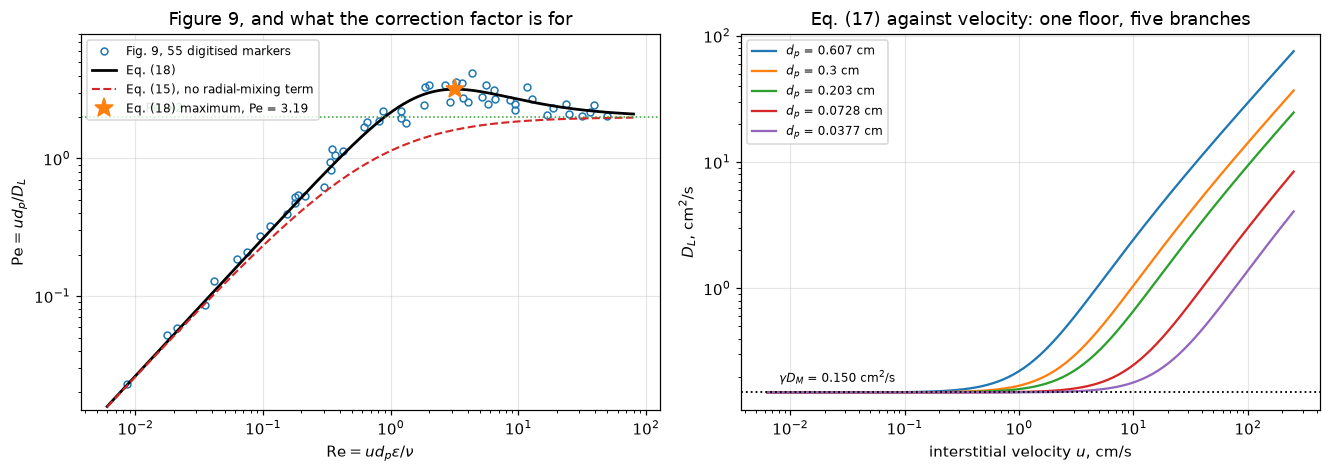


**30 of the 55 digitised points lie above $\mathrm{Pe} = 2$**,
the largest at 4.16. Eq. (15), molecular diffusion plus an
uncorrected eddy term, has a supremum of exactly 2 and can
therefore not produce any of them. That is not a matter of fitted constants: the
eddy coefficient is $\tfrac12$ *because* the mixing-cell limit is
$\mathrm{Pe} = 2$, so no choice of $\gamma$ moves the ceiling. The maximum is
the evidence for a third mechanism, and it is why the paper has an Eq. (16).


In [9]:
Re_d, Pe_d = fig9.reynolds.to_numpy(), fig9.peclet.to_numpy()
Re_grid = np.logspace(np.log10(0.006), np.log10(80), 400)
PE_CEIL = 1.0 / C_EDDY                     # the supremum of Eq. (15)


def Pe_eq15(Re, A=A_printed):
    """Eq. (15): Eq. (16) with the correction factor removed, i.e. beta = 0."""
    return 1.0 / (A / Re + C_EDDY)


fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
ax = axes[0]
ax.loglog(Re_d, Pe_d, "o", ms=4.5, mfc="none", color="tab:blue",
          label=f"Fig. 9, {len(Re_d)} digitised markers")
ax.loglog(Re_grid, Pe_eq18(Re_grid), "-", color="k", lw=1.8, label="Eq. (18)")
ax.loglog(Re_grid, Pe_eq15(Re_grid), "--", color="tab:red", lw=1.4,
          label="Eq. (15), no radial-mixing term")
ax.axhline(PE_CEIL, color="tab:green", lw=1.0, ls=":")
ax.text(0.012, 2.15, r"$\mathrm{Pe}\to 2$", color="tab:green", fontsize=8)
ax.plot([Re_star], [Pe_star], "*", ms=13, color="tab:orange", zorder=5,
        label=f"Eq. (18) maximum, Pe = {Pe_star:.2f}")
ax.set(xlabel=r"$\mathrm{Re}=u d_p \varepsilon/\nu$",
       ylabel=r"$\mathrm{Pe}=u d_p/D_L$", ylim=(0.015, 8),
       title="Figure 9, and what the correction factor is for")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
u_grid = np.logspace(-2.2, 2.4, 300)          # interstitial velocity, cm/s
for _, row in big.iterrows():
    dp = row.d_p_cm
    ax.loglog(u_grid, D_L_eq17(u_grid, dp), lw=1.5, label=f"$d_p$ = {dp} cm")
ax.axhline(gamma * D_M, color="k", lw=1.2, ls=":")
ax.text(0.008, gamma * D_M * 1.2,
        r"$\gamma D_M$ = " + f"{gamma * D_M:.3f}" + r" cm$^2$/s", fontsize=8)
ax.set(xlabel=r"interstitial velocity $u$, cm/s", ylabel=r"$D_L$, cm$^2$/s",
       title="Eq. (17) against velocity: one floor, five branches")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

n_above2 = int((Pe_d > PE_CEIL).sum())
display(Markdown(rf"""
**{n_above2} of the {len(Pe_d)} digitised points lie above $\mathrm{{Pe}} = {PE_CEIL:.0f}$**,
the largest at {Pe_d.max():.2f}. Eq. (15), molecular diffusion plus an
uncorrected eddy term, has a supremum of exactly {PE_CEIL:.0f} and can
therefore not produce any of them. That is not a matter of fitted constants: the
eddy coefficient is $\tfrac12$ *because* the mixing-cell limit is
$\mathrm{{Pe}} = 2$, so no choice of $\gamma$ moves the ceiling. The maximum is
the evidence for a third mechanism, and it is why the paper has an Eq. (16).
"""))

### The experiment, simulated

The forward problem at the conditions of their Figure 13: two response curves
at the printed separation, the moments of each, and Eqs. (6) and (7) applied to
the differences. Note how much of the second curve's width is inherited from the
first: that is exactly what the subtraction removes.

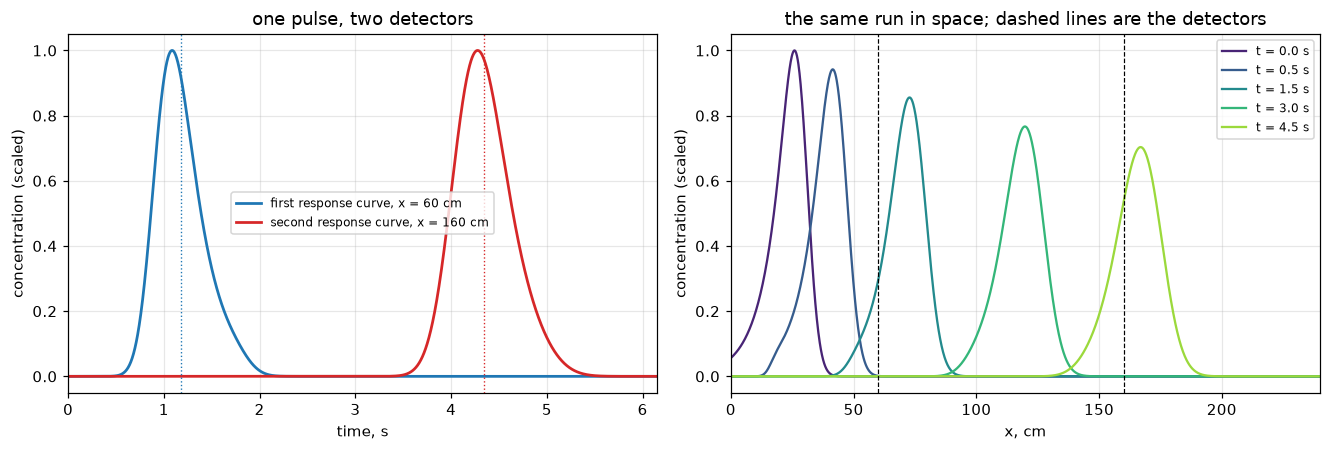


| quantity | first curve | second curve | difference | E&R |
|---|---|---|---|---|
| area $A$ | 0.030786 | 0.030786 | ratio 1.00000053 | Eq. (5), $A_1=A_2$ |
| mean, s | 1.1819 | 4.3479 | 3.1660 | Eq. (6), $\Delta x/u$ = 3.1660 |
| variance, s² | 0.06469 | 0.09048 | 0.02580 | Eq. (7), $2D_L\Delta x/u^3$ = 0.02579 |

Inverting the two differences with Eqs. (6) and (7) on 1600 cells returns
$u$ = 31.60106 cm/s against the 31.60104 cm/s put in
(4.9e-07 relative) and $D_L$ = 4.06839 cm²/s against
4.06794 (1.1e-04). The second curve's variance is
1.4 times the first's, but only 29% of it is
what the bed between the detectors did; the rest is the injected pulse, and it
cancels.


In [10]:
N13 = 1600
RUN1600 = simulate_experiment(U13, D13, dx_probe=DX13, n=N13, theta=0.5)
bed, t, c1, c2, dx13 = RUN1600
u_hat, D_hat, A1, A2 = invert_two_point(t, c1, c2, dx13)
A1m, t1m, s1m = moments(t, c1)
A2m, t2m, s2m = moments(t, c2)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
ax = axes[0]
ax.plot(t, c1 / c1.max(), color="tab:blue", lw=1.8,
        label=f"first response curve, x = {X1:.0f} cm")
ax.plot(t, c2 / c2.max(), color="tab:red", lw=1.8,
        label=f"second response curve, x = {X1 + DX13:.0f} cm")
for tt, col in ((t1m, "tab:blue"), (t2m, "tab:red")):
    ax.axvline(tt, color=col, lw=0.9, ls=":")
ax.set(xlabel="time, s", ylabel="concentration (scaled)",
       title="one pulse, two detectors", xlim=(0, t2m + 6 * np.sqrt(s2m)))
ax.legend(fontsize=8)

ax = axes[1]
b2 = TracerBed(bed.L, N13, U13, D13)
cs = emg(b2.x_c, X0, SIGMA, TAIL)
scale = cs.max()
dt2 = 0.5 * b2.h / U13
tt = 0.0
snaps = [0.0, 0.5, 1.5, 3.0, 4.5]
for target, col in zip(snaps, plt.cm.viridis(np.linspace(0.1, 0.85, len(snaps)))):
    while tt < target - 1e-12:
        cs = b2.step(cs, dt2, theta=0.5)
        tt += dt2
    ax.plot(b2.x_c, cs / scale, color=col, lw=1.5, label=f"t = {target:.1f} s")
for xx in (X1, X1 + DX13):
    ax.axvline(xx, color="k", lw=0.8, ls="--")
ax.set(xlabel="x, cm", ylabel="concentration (scaled)", xlim=(0, bed.L),
       title="the same run in space; dashed lines are the detectors")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

display(Markdown(rf"""
| quantity | first curve | second curve | difference | E&R |
|---|---|---|---|---|
| area $A$ | {A1m:.6g} | {A2m:.6g} | ratio {A2m / A1m:.8f} | Eq. (5), $A_1=A_2$ |
| mean, s | {t1m:.4f} | {t2m:.4f} | {t2m - t1m:.4f} | Eq. (6), $\Delta x/u$ = {dx13 / U13:.4f} |
| variance, s² | {s1m:.5f} | {s2m:.5f} | {s2m - s1m:.5f} | Eq. (7), $2D_L\Delta x/u^3$ = {2 * D13 * dx13 / U13 ** 3:.5f} |

Inverting the two differences with Eqs. (6) and (7) on {N13} cells returns
$u$ = {u_hat:.5f} cm/s against the {U13:.5f} cm/s put in
({abs(dev(u_hat, U13)):.1e} relative) and $D_L$ = {D_hat:.5f} cm²/s against
{D13:.5f} ({abs(dev(D_hat, D13)):.1e}). The second curve's variance is
{s2m / s1m:.1f} times the first's, but only {(s2m - s1m) / s2m:.0%} of it is
what the bed between the detectors did; the rest is the injected pulse, and it
cancels.
"""))

### What the grid measures instead of the bed

That recovery is not free. A first-order upwind convective flux adds a numerical
diffusivity $u h/2$, and a $\theta$-method in time adds $(\theta-\tfrac12)u^2
\Delta t$, for implicit Euler $u^2\Delta t/2$. Neither is distinguishable from
physical dispersion by *any* measurement, because they enter the equation in
exactly the same place. So a tracer experiment simulated on a coarse grid
**reports its own truncation error as a dispersion coefficient**.

`A2.1` measures the steady-state version of this ($u\,\mathrm dz/2$ masquerading
as a lower Péclet number). Here it is in the transient inverse problem, and it
is quantitative: the prediction is made before the runs, with no fitted
constant.

In [11]:
LADDER = (400, 800, 1600, 3200)
SCHEMES = (("upwind, implicit Euler", None, 1.0),
           ("van Leer, implicit Euler", vanleer, 1.0),
           ("van Leer, Crank-Nicolson", vanleer, 0.5))
CFL = 0.5


def predicted_excess(h, limiter, theta, u=U13, cfl=CFL):
    """u h/2 for upwind plus (theta - 1/2) u^2 dt, dt = cfl h/u."""
    return (0.0 if limiter is not None else u * h / 2.0) + (theta - 0.5) * u ** 2 * cfl * h / u


rows = []
for n in LADDER:
    for tag, lim, th in SCHEMES:
        run = (RUN800 if (n, lim, th) == (N_ROUTE, vanleer, 0.5) else
               RUN1600 if (n, lim, th) == (N13, vanleer, 0.5) else
               simulate_experiment(U13, D13, dx_probe=DX13, n=n, cfl=CFL, theta=th,
                                   limiter=lim))
        uh, Dh, _, _ = invert_two_point(*run[1:])
        rows.append(dict(scheme=tag, n=n, h=run[0].h, D_hat=Dh, excess=Dh - D13, u_err=uh / U13 - 1,
                         predicted=predicted_excess(run[0].h, lim, th)))
tab = pd.DataFrame(rows)
tab["ratio"] = np.where(tab.predicted > 0, tab.excess / tab.predicted, np.nan)
tab["rel_err"] = np.abs(tab.D_hat / D13 - 1.0)

for tag, g in tab.groupby("scheme", sort=False):
    print(tag)
    for _, r in g.iterrows():
        extra = (f"predicted {r.predicted:8.5f}  ratio {r.ratio:6.4f}"
                 if r.predicted > 0 else "predicted 0 (both terms switched off)")
        print(f"   n = {int(r.n):5d}  h = {r.h:7.4f}  D_hat = {r.D_hat:9.5f}"
              f"  excess {r.excess:+9.5f}  {extra}")
    print()


def local_orders(err, h):
    err, h = np.asarray(err, float), np.asarray(h, float)
    return np.log(err[:-1] / err[1:]) / np.log(h[:-1] / h[1:])


cn = tab[tab.scheme == "van Leer, Crank-Nicolson"]
ie = tab[tab.scheme == "van Leer, implicit Euler"]
ORD_CN = local_orders(cn.rel_err, cn.h)
ORD_IE = local_orders(ie.rel_err, ie.h)
with_pred = tab.dropna(subset=["ratio"])
worst_ratio = float(np.abs(with_pred.ratio - 1).max())
coarse = tab.query("scheme == 'upwind, implicit Euler' and n == 400").D_hat.iloc[0]
ERR_CN_FINEST = float(cn[cn.n == LADDER[-1]].rel_err.iloc[0])
print("van Leer, Crank-Nicolson, observed order between successive grids: "
      + ", ".join(f"{o:.2f}" for o in ORD_CN))
display(Markdown(rf"""
The predicted excess is $u h/2$ for upwind plus $u^2\Delta t/2$ for implicit
Euler, with no fitted constant anywhere, and it accounts for the measured excess
to within **{worst_ratio:.1%}** over {len(with_pred)} runs and a factor of
{LADDER[-1] // LADDER[0]} in grid spacing. Switch both off (van Leer plus
Crank-Nicolson) and the recovered $D_L$ converges on the input at an observed
order between **{ORD_CN.min():.2f} and {ORD_CN.max():.2f}** on successive grids,
reaching {ERR_CN_FINEST:.1e} relative at $n$ = {LADDER[-1]}.

Read the first row the other way round and it is a warning about the
*experiment*, not about the code. A dispersion coefficient inferred from a pulse
is only as good as the resolution of whatever propagates it: at $n$ = {LADDER[0]}
the answer is {coarse / D13:.1f} times the truth, and the response curves it came
from look perfectly smooth.
"""))

upwind, implicit Euler
   n =   400  h =  0.6000  D_hat =  18.28841  excess +14.22047  predicted 14.22047  ratio 1.0000
   n =   800  h =  0.3000  D_hat =  11.17818  excess  +7.11023  predicted  7.11023  ratio 1.0000
   n =  1600  h =  0.1500  D_hat =   7.62306  excess  +3.55512  predicted  3.55512  ratio 1.0000
   n =  3200  h =  0.0750  D_hat =   5.84550  excess  +1.77756  predicted  1.77756  ratio 1.0000

van Leer, implicit Euler
   n =   400  h =  0.6000  D_hat =   8.82805  excess  +4.76011  predicted  4.74016  ratio 1.0042
   n =   800  h =  0.3000  D_hat =   6.44093  excess  +2.37298  predicted  2.37008  ratio 1.0012
   n =  1600  h =  0.1500  D_hat =   5.25338  excess  +1.18544  predicted  1.18504  ratio 1.0003
   n =  3200  h =  0.0750  D_hat =   4.66052  excess  +0.59257  predicted  0.59252  ratio 1.0001

van Leer, Crank-Nicolson
   n =   400  h =  0.6000  D_hat =   4.09747  excess  +0.02952  predicted 0 (both terms switched off)
   n =   800  h =  0.3000  D_hat =   4.07151  e


The predicted excess is $u h/2$ for upwind plus $u^2\Delta t/2$ for implicit
Euler, with no fitted constant anywhere, and it accounts for the measured excess
to within **0.4%** over 8 runs and a factor of
8 in grid spacing. Switch both off (van Leer plus
Crank-Nicolson) and the recovered $D_L$ converges on the input at an observed
order between **2.99 and 3.05** on successive grids,
reaching 1.4e-05 relative at $n$ = 3200.

Read the first row the other way round and it is a warning about the
*experiment*, not about the code. A dispersion coefficient inferred from a pulse
is only as good as the resolution of whatever propagates it: at $n$ = 400
the answer is 4.5 times the truth, and the response curves it came
from look perfectly smooth.


### Where the correlation says dispersion matters

Eq. (17) is usually wanted for one purpose: deciding whether a bed can be
treated as plug flow. The bed Péclet number is $\mathrm{Pe}_L = uL/D_L =
(L/d_p)\,\mathrm{Pe}$, so the correlation and the aspect ratio settle it between
them. What a given $\mathrm{Pe}_L$ then does to conversion is
[`A2.1`](../A2.1-danckwerts-boundary-conditions/)'s subject and is not rebuilt
here.

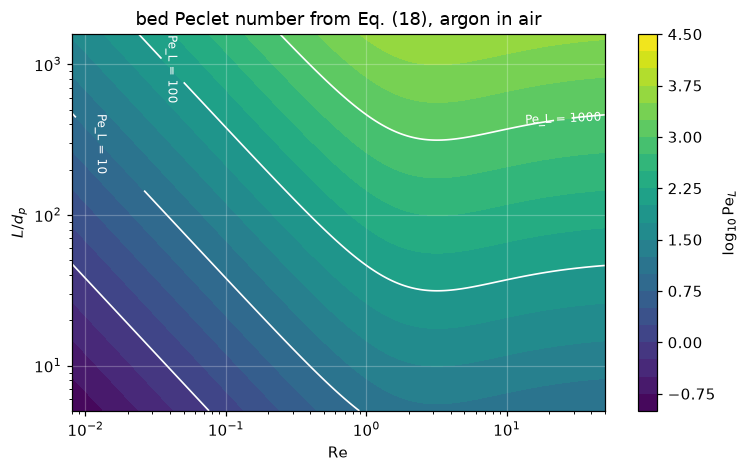


The map is read along a horizontal line. A bed 100 particles deep runs at
$\mathrm{Pe}_L$ = 2.6 at $\mathrm{Re}$ = 0.01 but
269 at $\mathrm{Re}$ = 10: the *same bed*, two orders of
magnitude apart in how nearly it is plug flow, because at low Reynolds number
$D_L$ stops falling with velocity and sits on the molecular floor
$\gamma D_M$ = 0.150 cm²/s. Reaching $\mathrm{Pe}_L$ =
100 needs $L/d_p$ = 3800 at $\mathrm{Re}$ = 0.01
and only 31 at the Péclet maximum, $\mathrm{Re}$ = 3.2.

That is the practical content of the molecular-diffusion term, and it is why a
correlation carrying only the eddy branch would mislead badly in exactly the
regime (slow flow, small particles) where laboratory reactors live.


In [12]:
L_over_dp = np.logspace(0.7, 3.2, 220)
Re_ax = np.logspace(np.log10(P["reynolds_min"]), np.log10(P["reynolds_max"]), 220)
G_R, G_L = np.meshgrid(Re_ax, L_over_dp)
PeL = G_L * Pe_eq18(G_R)

fig, ax = plt.subplots(figsize=(7.0, 4.4))
cf = ax.contourf(G_R, G_L, np.log10(PeL), levels=np.linspace(-1, 4.5, 23),
                 cmap="viridis")
cl = ax.contour(G_R, G_L, PeL, levels=[1, 10, 100, 1000], colors="w", linewidths=1.1)
ax.clabel(cl, fmt="Pe_L = %g", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel=r"$\mathrm{Re}$", ylabel=r"$L/d_p$",
       title="bed Peclet number from Eq. (18), argon in air")
fig.colorbar(cf, ax=ax, label=r"$\log_{10}\mathrm{Pe}_L$")
ax.grid(alpha=0.25, color="w")
fig.tight_layout()
plt.show()

RE_SLOW, RE_FAST, L_DP, PE_L_NEED = 0.01, 10.0, 100.0, 100.0


def plug_flow_numbers(A=A_printed, B=B_printed):
    """Pe_L of a bed L_DP particles deep at RE_SLOW and RE_FAST, and the depth
    that reaches PE_L_NEED at RE_SLOW and at the Peclet maximum."""
    Pe_s, Pe_f = Pe_eq18(RE_SLOW, A, B), Pe_eq18(RE_FAST, A, B)
    return L_DP * Pe_s, L_DP * Pe_f, PE_L_NEED / Pe_s, PE_L_NEED / Pe_max_eq18(A, B)[1]


PEL_SLOW, PEL_FAST, LDP_SLOW, LDP_MAX = plug_flow_numbers()
display(Markdown(rf"""
The map is read along a horizontal line. A bed {L_DP:.0f} particles deep runs at
$\mathrm{{Pe}}_L$ = {PEL_SLOW:.1f} at $\mathrm{{Re}}$ = {RE_SLOW} but
{PEL_FAST:.0f} at $\mathrm{{Re}}$ = {RE_FAST:.0f}: the *same bed*, two orders of
magnitude apart in how nearly it is plug flow, because at low Reynolds number
$D_L$ stops falling with velocity and sits on the molecular floor
$\gamma D_M$ = {gamma * D_M:.3f} cm²/s. Reaching $\mathrm{{Pe}}_L$ =
{PE_L_NEED:.0f} needs $L/d_p$ = {LDP_SLOW:.0f} at $\mathrm{{Re}}$ = {RE_SLOW}
and only {LDP_MAX:.0f} at the Péclet maximum, $\mathrm{{Re}}$ = {Re_star:.1f}.

That is the practical content of the molecular-diffusion term, and it is why a
correlation carrying only the eddy branch would mislead badly in exactly the
regime (slow flow, small particles) where laboratory reactors live.
"""))

### The fine-particle anomaly, and what their own diagnostic says about it

With the finest beads, the sand and the diakon, Edwards and Richardson's moment
analysis returned dispersion coefficients far above Eq. (17); Figure 15 prints
one such apparent $D_L$. They then applied their own consistency test,
computing the second response curve from the first with that $D_L$, and found
the *measured* curve peaked **earlier** than the computed one. They attributed
it to channelling: the materials "have a fair spread of particle sizes ... it is
thought that channels are being formed, the fine particles being swept aside
laterally".

The moment method cannot itself tell a genuinely larger $D_L$ from a velocity
distribution, because it only ever sees two moments. The shape can. So the
question a solver can answer is: **what velocity structure reproduces both their
$D_L$ and the sign of their shape discrepancy?** The model is `TwoZoneBed`,
with $\kappa$ set in every case so that the two-point moment method returns
their apparent $D_L$.

In [13]:
UMF15 = voidage_of(DP15, "u_mf_cm_s")
U_OVER_UMF15 = U15 * EPS15 / UMF15
print(f"Figure 15 conditions: d_p = {DP15} cm, Re = {RE15}, "
      f"apparent D_L = {DL15} cm2/s")
print(f"  voidage (Table 1)                       {EPS15}")
print(f"  interstitial velocity                   {U15:.4f} cm/s")
print(f"  superficial velocity                    {U15 * EPS15:.4f} cm/s")
print(f"  minimum fluidisation velocity (Table 1) {UMF15} cm/s"
      f"   -> the run sits at {U_OVER_UMF15:.0%} of it")
print(f"  Eq. (17) prediction                     {D15:.5f} cm2/s")
print(f"  measured / predicted                    {DL15 / D15:.2f}"
      f"   (deviation {dev(D15, DL15):+.1%})")

Figure 15 conditions: d_p = 0.0097 cm, Re = 0.071, apparent D_L = 0.503 cm2/s
  voidage (Table 1)                       0.41
  interstitial velocity                   2.6351 cm/s
  superficial velocity                    1.0804 cm/s
  minimum fluidisation velocity (Table 1) 1.23 cm/s   -> the run sits at 88% of it
  Eq. (17) prediction                     0.14981 cm2/s
  measured / predicted                    3.36   (deviation -70.2%)


In [14]:
# DX_ASSUMED. Figure 15's legend prints the bead size, the Reynolds number and
# the apparent D_L, and NOT the detector separation. E&R p. 111 say the test
# section was "either of two tubes", and their conclusions quote the range of
# separations. Everything below ASSUMES the section Figure 13 prints; the
# alternative is run at the end of this section, and it is not a small difference.
DX_ASSUMED = DX13
FLUX_FRACS = (0.01, 0.03, 0.05, 0.08, 0.25, 0.40, 0.60, 0.80)
N_FLUX = 800


def fine_case(flux_frac, **kw):
    """channelling_case at the Figure-15 conditions, tuned to E&R's apparent D_L."""
    kw.setdefault("dx_probe", DX_ASSUMED)
    return channelling_case(flux_frac, U15, D15, DL15, **kw)


def flux_scan(**kw):
    out = {ff: fine_case(ff, n=N_FLUX, **kw) for ff in FLUX_FRACS}
    df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("t", "sim", "comp", "first")}
                       for r in out.values()])
    df["u1_over_u"], df["u2_over_u"] = df.u1 / U15, df.u2 / U15
    df["slow_minority"] = df.u1 < df.u2          # zone 1 holds the minority volume
    return df, out


scan, SCAN_RUNS = flux_scan()
print(f"The minority zone holds {scan.th1.iloc[0]:.0%} of the void. kappa is set in every row")
print(f"so that the two-point moment method returns E&R's measured {DL15} cm2/s.\n")
print(scan[["flux_frac", "u1_over_u", "u2_over_u", "kappa", "D_hat", "lag", "resid"]]
      .to_string(index=False,
                 formatters={"flux_frac": "{:.2f}".format,
                             "u1_over_u": "{:.3f}".format,
                             "u2_over_u": "{:.3f}".format,
                             "kappa": "{:.3f}".format,
                             "D_hat": "{:.4f}".format,
                             "lag": "{:+.2%}".format,
                             "resid": "{:.1%}".format}))

The minority zone holds 15% of the void. kappa is set in every row
so that the two-point moment method returns E&R's measured 0.503 cm2/s.

flux_frac u1_over_u u2_over_u kappa  D_hat    lag resid
     0.01     0.067     1.165 0.385 0.5033 +0.23%  3.3%
     0.03     0.200     1.141 0.283 0.5033 +0.27%  3.8%
     0.05     0.333     1.118 0.197 0.5033 +0.32%  4.5%
     0.08     0.533     1.082 0.096 0.5033 +0.36%  6.3%
     0.25     1.667     0.882 0.197 0.5032 -0.23%  3.6%
     0.40     2.667     0.706 1.229 0.5032 -0.11%  1.2%
     0.60     4.000     0.471 3.981 0.5032 -0.04%  0.6%
     0.80     5.333     0.235 8.306 0.5032 -0.03%  0.3%


In [15]:
# The scan above holds the minority VOLUME fixed and moves the flow split. That
# is one slice of the parameter space, and the peak displacement it bounds is a
# maximum over that slice only. Here the volume fraction moves too, with the
# velocity RATIO held fixed, so that every row is still tuned to the same
# measured D_L. Both directions are run: the minority zone slow, and fast.
#
# A bed with (th1, u1/u2) is the bed (1 - th1, u2/u1) with the zones renamed, so
# only th1 < 0.5 is scanned: the other half would repeat each bed. The cell
# checks that once.
SLOW, FAST = 0.2, 5.0                          # u1/u2 for the two directions
TH_SCAN = (0.03, 0.05, 0.15, 0.35)
N_SPLIT, N_COARSE, N_FINE = 1000, 500, 2000     # production grid, and the ladder
LAG_FLOOR = 0.0005                             # 0.05 % of the transit time


def split_case(th1, ratio, n=N_SPLIT, **kw):
    return two_zone_split(th1, ratio, U15, D15, DL15, n=n, dx_probe=DX_ASSUMED, **kw)


def split_scan(n=N_SPLIT, **kw):
    rows = []
    for th1 in TH_SCAN:
        for ratio in (SLOW, FAST):
            r = split_case(th1, ratio, n=n, **kw)
            # zone 1 is the minority by volume here, so it is slow when ratio < 1
            rows.append(dict(th1=th1, ratio=ratio, minority_slow=ratio < 1.0,
                             D_hat=r["D_hat"], lag=r["lag"], resid=r["resid"]))
    df = pd.DataFrame(rows)
    df["expected_sign"] = np.where(df.minority_slow, 1.0, -1.0)
    df["sign_ok"] = np.sign(df.lag) == df.expected_sign
    return df


th_scan = split_scan()
th_coarse = split_scan(n=N_COARSE)            # the coarse rung of the ladder
_ref, _mirror = split_case(0.15, SLOW), split_case(0.85, FAST)
MIRROR_GAP = abs(_mirror["lag"] - _ref["lag"]) + abs(_mirror["resid"] - _ref["resid"])
print("Volume split scanned at fixed velocity ratio; kappa retuned every row.")
print("'minority_slow' is whether the zone holding LESS of the void is the slower one;")
print(f"'sign_ok' is whether the computed peak then lags, as E&R report. n = {N_SPLIT}.\n")
print(th_scan.drop(columns="expected_sign").assign(lag_n500=th_coarse.lag).to_string(
    index=False, formatters={"th1": "{:.2f}".format, "ratio": "{:.1f}".format,
                             "D_hat": "{:.4f}".format, "lag": "{:+.3%}".format,
                             "lag_n500": "{:+.3%}".format, "resid": "{:.1%}".format}))
print(f"\nthe same bed with the zones renamed, th1 = 0.85 at u1/u2 = {FAST:g} against"
      f" th1 = 0.15 at {SLOW:g}: lag and residual differ by (here {MIRROR_GAP:.1e})")
sign_ok = int(th_scan.sign_ok.sum())
sign_ok_coarse = int(th_coarse.sign_ok.sum())
flux_ok = int((np.sign(scan.lag) == np.where(scan.slow_minority, 1, -1)).sum())
above = th_scan[th_scan.lag.abs() > LAG_FLOOR]
bad_coarse = th_coarse[~th_coarse.sign_ok]
print(f"\nsign follows minority-by-volume-slow in {sign_ok} of {len(th_scan)}"
      f" beds here and {flux_ok} of {len(scan)} in the flux scan above;")
print(f"{len(above)} of the {len(th_scan)} beds displace the peak by more than {LAG_FLOOR:.2%}.")
print(f"on {N_COARSE} cells the sign rule holds in {sign_ok_coarse} of {len(th_coarse)}; the"
      " exception(s) at th1 = " + (", ".join(f"{v:.2f}" for v in bad_coarse.th1) or "none")
      + " are the coarse grid's.")
LAG_MAX_CLASS = float(th_scan.lag.abs().max())
LAG_MAX_SLICE = float(scan.lag.abs().max())
print(f"largest peak lag anywhere: {LAG_MAX_CLASS:.2%} of the transit"
      f" time, at th1 = {th_scan.loc[th_scan.lag.abs().idxmax(), 'th1']:.2f};"
      f"  largest shape residual: {th_scan.resid.max():.1%} of peak")
print(f"the th1 = {TH1} slice reported above tops out at"
      f" {LAG_MAX_SLICE:.2%} and {scan.resid.max():.1%}, so a maximum over one slice")
print("is not a maximum over the model class (the ratio on matched grids follows).")

# The ladder: every bed of the split scan one grid finer, and the flow-scan maximum
# with the split-scan maximum on matched grids.
th_fine = split_scan(n=N_FINE)
LAG_CHANGE = (th_fine.lag / th_scan.lag - 1).abs()
LAG_CHANGE_COARSE = (th_scan.lag / th_coarse.lag - 1).abs()
SIGN_OK_FINE = int(th_fine.sign_ok.sum())
ABOVE_FINE = th_fine[th_fine.lag.abs() > LAG_FLOOR]
I_MAX = int(th_scan.lag.abs().idxmax())          # the bed of the largest lag
RESID_CHANGE = abs(th_fine.resid.iloc[I_MAX] / th_scan.resid.iloc[I_MAX] - 1)
RESID_CHANGE_COARSE = abs(th_scan.resid.iloc[I_MAX] / th_coarse.resid.iloc[I_MAX] - 1)
print(f"\nthe split scan on {N_COARSE}, {N_SPLIT} and {N_FINE} cells:")
print(th_scan[["th1", "ratio", "minority_slow"]].assign(
    lag_n500=th_coarse.lag, lag_n1000=th_scan.lag, lag_n2000=th_fine.lag,
    change=LAG_CHANGE).to_string(index=False, formatters={
        "th1": "{:.2f}".format, "ratio": "{:.1f}".format, "lag_n500": "{:+.3%}".format,
        "lag_n1000": "{:+.3%}".format, "lag_n2000": "{:+.3%}".format,
        "change": "{:.1%}".format}))
CHANGE_SLOW = float(LAG_CHANGE[th_scan.minority_slow].max())
CHANGE_FAST = float(LAG_CHANGE[~th_scan.minority_slow].max())
print(f"largest change of a lag from {N_SPLIT} to {N_FINE} cells: {CHANGE_FAST:.0%} where the"
      f" minority zone is fast, {CHANGE_SLOW:.1%} where it is slow;")
print(f"on {N_FINE} cells the sign rule holds in {SIGN_OK_FINE} of {len(th_fine)} beds,"
      f" {len(ABOVE_FINE)} of them above {LAG_FLOOR:.2%}; the largest residual moves by"
      f" {RESID_CHANGE:.1%}.")

N_MATCH = (2 * N_FLUX, 4 * N_FLUX)               # 1600 and 3200 cells, for both scans
FF_MAX = float(scan.loc[scan.lag.abs().idxmax(), "flux_frac"])
_th_max, _r_max = th_scan.th1.iloc[I_MAX], th_scan.ratio.iloc[I_MAX]
MATCH = {n: (abs(split_case(_th_max, _r_max, n=n)["lag"]), abs(fine_case(FF_MAX, n=n)["lag"]))
         for n in N_MATCH}
print(f"\nmatched grids: largest split-scan lag (th1 = {_th_max:.2f}, u1/u2 = {_r_max:g}) and"
      f" largest flow-scan lag (share {FF_MAX:.2f})")
print(f"   n = {N_FLUX:5d} / {N_SPLIT}: {LAG_MAX_CLASS:.3%} and {LAG_MAX_SLICE:.3%} (the scans above)")
for n, (lc, ls) in MATCH.items():
    print(f"   n = {n:5d}:        {lc:.3%} and {ls:.3%}, ratio {lc / ls:.2f}")
RATIO_MATCH = {n: lc / ls for n, (lc, ls) in MATCH.items()}
LAG_SLICE_FINE = MATCH[N_MATCH[-1]][1]
LAG_CLASS_FINE = MATCH[N_MATCH[-1]][0]

Volume split scanned at fixed velocity ratio; kappa retuned every row.
'minority_slow' is whether the zone holding LESS of the void is the slower one;
'sign_ok' is whether the computed peak then lags, as E&R report. n = 1000.

 th1 ratio  minority_slow  D_hat     lag resid  sign_ok lag_n500
0.03   0.2           True 0.5032 +1.330% 18.0%     True  +1.139%
0.03   5.0          False 0.5031 -0.330%  4.9%     True  -0.215%
0.05   0.2           True 0.5032 +1.063% 12.8%     True  +0.981%
0.05   5.0          False 0.5031 -0.195%  3.0%     True  -0.129%
0.15   0.2           True 0.5031 +0.279%  3.7%     True  +0.164%
0.15   5.0          False 0.5031 -0.113%  1.0%     True  -0.114%
0.35   0.2           True 0.5031 +0.055%  0.9%     True  -0.011%
0.35   5.0          False 0.5031 -0.024%  0.2%     True  -0.004%

the same bed with the zones renamed, th1 = 0.85 at u1/u2 = 5 against th1 = 0.15 at 0.2: lag and residual differ by (here 7.0e-15)

sign follows minority-by-volume-slow in 8 of 8 beds here


the split scan on 500, 1000 and 2000 cells:
 th1 ratio  minority_slow lag_n500 lag_n1000 lag_n2000 change
0.03   0.2           True  +1.139%   +1.330%   +1.350%   1.5%
0.03   5.0          False  -0.215%   -0.330%   -0.385%  16.9%
0.05   0.2           True  +0.981%   +1.063%   +1.084%   1.9%
0.05   5.0          False  -0.129%   -0.195%   -0.246%  26.1%
0.15   0.2           True  +0.164%   +0.279%   +0.293%   4.9%
0.15   5.0          False  -0.114%   -0.113%   -0.112%   0.9%
0.35   0.2           True  -0.011%   +0.055%   +0.059%   7.9%
0.35   5.0          False  -0.004%   -0.024%   -0.035%  47.8%
largest change of a lag from 1000 to 2000 cells: 48% where the minority zone is fast, 7.9% where it is slow;
on 2000 cells the sign rule holds in 8 of 8 beds, 7 of them above 0.05%; the largest residual moves by 1.2%.



matched grids: largest split-scan lag (th1 = 0.03, u1/u2 = 0.2) and largest flow-scan lag (share 0.08)
   n =   800 / 1000: 1.330% and 0.360% (the scans above)
   n =  1600:        1.348% and 0.460%, ratio 2.93
   n =  3200:        1.345% and 0.493%, ratio 2.73


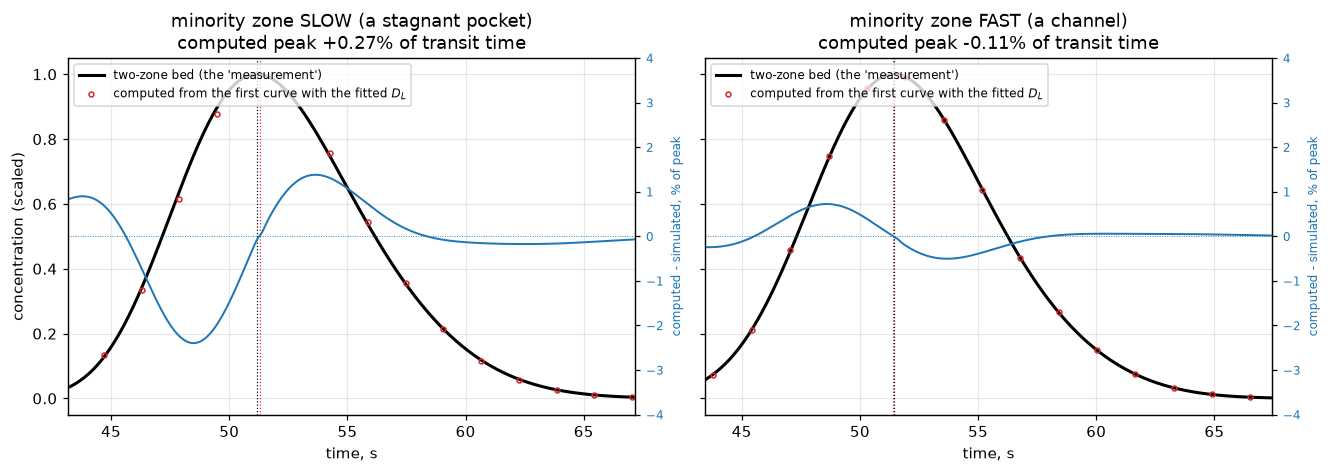


**The sign of E&R's shape discrepancy picks out the slow zone, not the fast
one.** Constrained to reproduce their measured $D_L$ = 0.503 cm²/s, the
two-zone bed makes the computed curve peak *later* than the simulated one (the
sense they report) only when the zone holding the smaller share of the void is
the **slower** one. With a fast channel the sign is the wrong way round in every
case tried, between -0.23% and -0.03%. Nor is it
an artefact of the injected pulse: repeating the two runs with a nearly symmetric
injection instead of the long-tailed one gives +0.38% and
-0.15%, the same signs.

**How far that generalises, tested rather than assumed.** Scanning the volume
split as well ($\theta_1$ from 0.03 to 0.35 in zone 1,
each direction, every bed still tuned to the same measured $D_L$, and each bed
counted once, since $(\theta_1, u_1/u_2)$ and $(1-\theta_1, u_2/u_1)$ are the
same bed), the sign follows minority-by-volume-slow in **8 of
8** beds on 1000 cells, including the ones where the minority
zone is the fast one; 7 of them displace the peak by more than
0.05% of the transit time. On 500 cells the rule fails in
1 bed(s), at $\theta_1$ =
0.35, where the lag is
small; refined, the sign is the rule's. On 2000 cells it holds in
8 of 8, 7 of them above the floor. The
lags themselves are values at their grid. Every bed was run one grid finer: where
the minority zone is slow the lag changes by at most 7.9%, where it is
fast by up to 48%, so the fast-minority lags are grid values good
to about 48%, not converged numbers. No sign changes. So the claim the page makes is the conditional one: *when* a
two-zone bed at this $D_L$ displaces the peak measurably, the direction E&R
report is the one a slow minority zone gives.

**What is small is the peak displacement, not the asymmetry, and how small
depends on where you look.** At the published slice, $\theta_1$ = 0.15, the
largest lag is 0.36% of the transit time on 800 cells and
0.49% on 3200, far below what a chart recorder
resolves. That is a maximum over one slice, not over the model class: letting
the volume fraction move as well, still tuned to the same measured $D_L$, reaches
**1.33%** at $\theta_1$ = 0.03 (1.34% on
3200 cells). On matched grids the ratio of the two maxima is
2.93 on 1600 cells and
2.73 on 3200, and the shape residual reaches
18.0% of peak (it moves by 1.2% on 2000 cells). So the peak displacement bounds
nothing about the model class; what it says is that in the regime E&R's own
picture describes, the discrepancy is mostly *shape*. The blue traces above are
the computed curve minus the simulated one, spanning 3.8% of the peak
in the slow case against 1.2% in the fast one.

**Is that visible to them?** Not answerable from the paper, and the page does
not claim it is. Appendix A gives percentage standard deviations of a five-pulse
average (1.37 % in area and
1.3 % in variance), but those are the scatter of
*integrated moments*, and a residual of a few per cent of the peak is a
*pointwise* quantity. The two are not commensurable: a standard deviation
on an integral bounds pointwise noise neither above nor below. The only
pointwise statement in the paper is that below about $c_\mathrm{max}$/30 "the
noise level becomes too great for accurate measurements" (p. 114), which is a
statement about the tail, not the peak. So the residual is **comparable to, but
not demonstrably above, their reported reproducibility**, and what a two-zone
bed at their measured $D_L$ produces is a discrepancy of the size they would
have had to argue about, not one this page can show they must have seen.

**Δx is assumed, and it matters.** Figure 15's legend prints 0.0097 cm beads,
$\mathrm{Re}$ = 0.071 and $D_L$ = 0.503 cm²/s, and **not** the detector
separation. Everything above takes $\Delta x$ = 100 cm, which is
what Figure 13 prints for the large-particle run; the paper's other test section
was 21.3 cm. At 100 cm the response curve has
$\sigma/\bar t$ = 6.2%, close to plug flow, so there is not much shape for
a velocity distribution to distort. At 21.3 cm it is 13.4%,
2.2 times larger, so that argument would be weaker at the
shorter section, but running it is not the same as arguing it. The same
slow-zone case at 21.3 cm gives a lag of +0.23% against
+0.27%, and a shape residual of 1.7% of peak against
3.8%: the sign is unchanged and the discrepancy gets
**smaller**, because the shorter
section also gives the two zones less distance in which to differentiate. The
$\sigma/\bar t$ scaling alone predicts the wrong direction here, which is the
reason to run the alternative rather than reason about it. What survives either
way: the sign, and the fact that the shape residual is much larger than the peak
displacement.

A discrepancy large enough to see on a chart recorder therefore implies
**either** a slow region rather than a channel, **or** structure coarser than
any two-zone description tuned to 0.503 cm²/s can hold, for instance an
exchange so slow that the apparent $D_L$ is still growing with bed length, which
the two-point method would faithfully report as a length-dependent "dispersion
coefficient". The scan does not choose between those two branches, and the
metadata for this page must not either.

E&R checked for a length dependence and found none, but only for the *large*
particles, over 21.3 to 121.3 cm. For the fine particles the check is
not reported, and it is exactly the measurement that would settle both this and
the $\Delta x$ assumption above.

**What this does not do.** It does not fit their response curves: those are not
tabulated and Figure 15's abscissa carries no scale. It reproduces the sign and
the order of magnitude of a diagnostic from their printed $D_L$ and their
printed conditions, and it says which of two channelling pictures is consistent
with it.


In [16]:
FF_SLOW, FF_FAST = 0.03, 0.40
slow, fast = SCAN_RUNS[FF_SLOW], SCAN_RUNS[FF_FAST]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), sharey=True)
for ax, case, ttl in ((axes[0], slow, "minority zone SLOW (a stagnant pocket)"),
                      (axes[1], fast, "minority zone FAST (a channel)")):
    t_, sim, comp = case["t"], case["sim"], case["comp"]
    pk = sim.max()
    ax.plot(t_, sim / pk, color="k", lw=2.0,
            label="two-zone bed (the 'measurement')")
    ax.plot(t_, comp / comp.max(), "o", ms=3.2, mfc="none", color="tab:red",
            markevery=max(1, len(t_) // 60),
            label=r"computed from the first curve with the fitted $D_L$")
    ax.axvline(peak_time(t_, sim), color="k", lw=0.8, ls=":")
    ax.axvline(peak_time(t_, comp), color="tab:red", lw=0.8, ls=":")
    lo = peak_time(t_, sim)
    ax2 = ax.twinx()
    ax2.plot(t_, 100 * (comp / comp.max() - sim / pk), color="tab:blue", lw=1.3)
    ax2.axhline(0.0, color="tab:blue", lw=0.6, ls=":")
    ax2.set_ylim(-4.0, 4.0)
    ax2.set_ylabel("computed - simulated, % of peak", color="tab:blue",
                   fontsize=8)
    ax2.tick_params(axis="y", labelcolor="tab:blue", labelsize=8)
    ax2.grid(False)
    ax.set(xlabel="time, s", xlim=(lo - 8, lo + 16),
           title=f"{ttl}\ncomputed peak {case['lag']:+.2%} of transit time")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("concentration (scaled)")
fig.tight_layout()
plt.show()

# is the sign an artefact of the injected pulse shape? repeat with a nearly symmetric one
TAIL_SYM = 0.4
sym_slow = fine_case(FF_SLOW, tail=TAIL_SYM, n=N_FLUX)
sym_fast = fine_case(FF_FAST, tail=TAIL_SYM, n=N_FLUX)


def sigma_over_tbar(dx, u=U15, D=DL15):
    """sqrt(2 D dx/u^3) / (dx/u) at E&R's apparent D_L: falls as dx^-1/2."""
    return np.sqrt(2 * D * dx / u ** 3) / (dx / u)


sig_t, sig_t_alt = sigma_over_tbar(DX_ASSUMED), sigma_over_tbar(DX_SHORT)
alt = fine_case(FF_SLOW, n=N_FLUX, dx_probe=DX_SHORT)
res_slow, res_fast = slow["resid"], fast["resid"]
fast_lags = scan.loc[~scan.slow_minority, "lag"]
display(Markdown(rf"""
**The sign of E&R's shape discrepancy picks out the slow zone, not the fast
one.** Constrained to reproduce their measured $D_L$ = {DL15} cm²/s, the
two-zone bed makes the computed curve peak *later* than the simulated one (the
sense they report) only when the zone holding the smaller share of the void is
the **slower** one. With a fast channel the sign is the wrong way round in every
case tried, between {fast_lags.min():+.2%} and {fast_lags.max():+.2%}. Nor is it
an artefact of the injected pulse: repeating the two runs with a nearly symmetric
injection instead of the long-tailed one gives {sym_slow['lag']:+.2%} and
{sym_fast['lag']:+.2%}, the same signs.

**How far that generalises, tested rather than assumed.** Scanning the volume
split as well ($\theta_1$ from {min(TH_SCAN):.2f} to {max(TH_SCAN):.2f} in zone 1,
each direction, every bed still tuned to the same measured $D_L$, and each bed
counted once, since $(\theta_1, u_1/u_2)$ and $(1-\theta_1, u_2/u_1)$ are the
same bed), the sign follows minority-by-volume-slow in **{sign_ok} of
{len(th_scan)}** beds on {N_SPLIT} cells, including the ones where the minority
zone is the fast one; {len(above)} of them displace the peak by more than
{LAG_FLOOR:.2%} of the transit time. On {N_COARSE} cells the rule fails in
{len(th_coarse) - sign_ok_coarse} bed(s), at $\theta_1$ =
{", ".join(f"{v:.2f}" for v in bad_coarse.th1) or "none"}, where the lag is
small; refined, the sign is the rule's. On {N_FINE} cells it holds in
{SIGN_OK_FINE} of {len(th_fine)}, {len(ABOVE_FINE)} of them above the floor. The
lags themselves are values at their grid. Every bed was run one grid finer: where
the minority zone is slow the lag changes by at most {CHANGE_SLOW:.1%}, where it is
fast by up to {CHANGE_FAST:.0%}, so the fast-minority lags are grid values good
to about {CHANGE_FAST:.0%}, not converged numbers. No sign changes. So the claim the page makes is the conditional one: *when* a
two-zone bed at this $D_L$ displaces the peak measurably, the direction E&R
report is the one a slow minority zone gives.

**What is small is the peak displacement, not the asymmetry, and how small
depends on where you look.** At the published slice, $\theta_1$ = {TH1}, the
largest lag is {LAG_MAX_SLICE:.2%} of the transit time on {N_FLUX} cells and
{LAG_SLICE_FINE:.2%} on {N_MATCH[-1]}, far below what a chart recorder
resolves. That is a maximum over one slice, not over the model class: letting
the volume fraction move as well, still tuned to the same measured $D_L$, reaches
**{LAG_MAX_CLASS:.2%}** at $\theta_1$ = {_th_max:.2f} ({LAG_CLASS_FINE:.2%} on
{N_MATCH[-1]} cells). On matched grids the ratio of the two maxima is
{RATIO_MATCH[N_MATCH[0]]:.2f} on {N_MATCH[0]} cells and
{RATIO_MATCH[N_MATCH[-1]]:.2f} on {N_MATCH[-1]}, and the shape residual reaches
{th_scan.resid.max():.1%} of peak (it moves by {RESID_CHANGE:.1%} on {N_FINE} cells). So the peak displacement bounds
nothing about the model class; what it says is that in the regime E&R's own
picture describes, the discrepancy is mostly *shape*. The blue traces above are
the computed curve minus the simulated one, spanning {res_slow:.1%} of the peak
in the slow case against {res_fast:.1%} in the fast one.

**Is that visible to them?** Not answerable from the paper, and the page does
not claim it is. Appendix A gives percentage standard deviations of a five-pulse
average ({P['percent_sd_pulse_area']} % in area and
{P['percent_sd_pulse_variance']} % in variance), but those are the scatter of
*integrated moments*, and a residual of a few per cent of the peak is a
*pointwise* quantity. The two are not commensurable: a standard deviation
on an integral bounds pointwise noise neither above nor below. The only
pointwise statement in the paper is that below about $c_\mathrm{{max}}$/30 "the
noise level becomes too great for accurate measurements" (p. 114), which is a
statement about the tail, not the peak. So the residual is **comparable to, but
not demonstrably above, their reported reproducibility**, and what a two-zone
bed at their measured $D_L$ produces is a discrepancy of the size they would
have had to argue about, not one this page can show they must have seen.

**Δx is assumed, and it matters.** Figure 15's legend prints {DP15} cm beads,
$\mathrm{{Re}}$ = {RE15} and $D_L$ = {DL15} cm²/s, and **not** the detector
separation. Everything above takes $\Delta x$ = {DX_ASSUMED:.0f} cm, which is
what Figure 13 prints for the large-particle run; the paper's other test section
was {DX_SHORT} cm. At {DX_ASSUMED:.0f} cm the response curve has
$\sigma/\bar t$ = {sig_t:.1%}, close to plug flow, so there is not much shape for
a velocity distribution to distort. At {DX_SHORT} cm it is {sig_t_alt:.1%},
{sig_t_alt / sig_t:.1f} times larger, so that argument would be weaker at the
shorter section, but running it is not the same as arguing it. The same
slow-zone case at {DX_SHORT} cm gives a lag of {alt['lag']:+.2%} against
{slow['lag']:+.2%}, and a shape residual of {alt['resid']:.1%} of peak against
{res_slow:.1%}: the sign is unchanged and the discrepancy gets
**{"smaller" if alt['resid'] < res_slow else "larger"}**, because the shorter
section also gives the two zones less distance in which to differentiate. The
$\sigma/\bar t$ scaling alone predicts the wrong direction here, which is the
reason to run the alternative rather than reason about it. What survives either
way: the sign, and the fact that the shape residual is much larger than the peak
displacement.

A discrepancy large enough to see on a chart recorder therefore implies
**either** a slow region rather than a channel, **or** structure coarser than
any two-zone description tuned to {DL15} cm²/s can hold, for instance an
exchange so slow that the apparent $D_L$ is still growing with bed length, which
the two-point method would faithfully report as a length-dependent "dispersion
coefficient". The scan does not choose between those two branches, and the
metadata for this page must not either.

E&R checked for a length dependence and found none, but only for the *large*
particles, over {DX_SHORT} to {DX_LONG} cm. For the fine particles the check is
not reported, and it is exactly the measurement that would settle both this and
the $\Delta x$ assumption above.

**What this does not do.** It does not fit their response curves: those are not
tabulated and Figure 15's abscissa carries no scale. It reproduces the sign and
the order of magnitude of a diagnostic from their printed $D_L$ and their
printed conditions, and it says which of two channelling pictures is consistent
with it.
"""))

In [17]:
umf_sand = float(tab1.loc[tab1.material == "sand", "u_mf_cm_s"].iloc[0])
umf_diakon = float(tab1.loc[tab1.material == "diakon", "u_mf_cm_s"].iloc[0])
display(Markdown(rf"""
### One number that bears on their explanation, from Table 1 alone, and the sentence that cuts against it

At $\mathrm{{Re}}$ = {RE15} the superficial velocity is {U15 * EPS15:.3f} cm/s,
and Table 1 gives the minimum fluidisation velocity of those same {DP15} cm
beads as {UMF15} cm/s. The anomalous run therefore sits at
**{U_OVER_UMF15:.0%} of incipient fluidisation**, a number the paper never
states, from two printed values on different pages, transcribed independently.

It is offered as corroboration because of what E&R write on p. 120: "the
transition is sharper with the material with the narrowest size range, occurring
only at velocities near those giving rise to bed expansion". But **the sentence
immediately before that one, in the same paragraph, points the other way**:
"However, this phenomenon occurs at velocities considerably below those at which
either bed expansion or fluidisation takes place."

Both sentences are printed, three lines apart, and the paper is in tension with
itself here. {U_OVER_UMF15:.0%} of $u_\mathrm{{mf}}$ is what the *quoted*
sentence would lead you to expect and is hard to call "considerably below", so
the number corroborates one half of the paragraph and sits awkwardly against the
other. Quoting only the half it agrees with would be the easy version of this
paragraph and the wrong one.

Two further limits on what {U_OVER_UMF15:.0%} can carry. Table 1 prints that
$u_\mathrm{{mf}}$ as the authors' own value for that size, and the anomaly is
reported for the sand and the diakon as well, whose tabulated $u_\mathrm{{mf}}$
are {umf_sand} and {umf_diakon} cm/s against Figure 15's single quoted run. So
what the number establishes is narrower than "the bed was near fluidisation": it
is that this particular run was not in a regime where incipient fluidisation is
orders of magnitude away, so a mechanism involving particle motion is not
excluded on velocity grounds, while the sentence above says the authors saw the
effect where it was.
"""))


### One number that bears on their explanation, from Table 1 alone, and the sentence that cuts against it

At $\mathrm{Re}$ = 0.071 the superficial velocity is 1.080 cm/s,
and Table 1 gives the minimum fluidisation velocity of those same 0.0097 cm
beads as 1.23 cm/s. The anomalous run therefore sits at
**88% of incipient fluidisation**, a number the paper never
states, from two printed values on different pages, transcribed independently.

It is offered as corroboration because of what E&R write on p. 120: "the
transition is sharper with the material with the narrowest size range, occurring
only at velocities near those giving rise to bed expansion". But **the sentence
immediately before that one, in the same paragraph, points the other way**:
"However, this phenomenon occurs at velocities considerably below those at which
either bed expansion or fluidisation takes place."

Both sentences are printed, three lines apart, and the paper is in tension with
itself here. 88% of $u_\mathrm{mf}$ is what the *quoted*
sentence would lead you to expect and is hard to call "considerably below", so
the number corroborates one half of the paragraph and sits awkwardly against the
other. Quoting only the half it agrees with would be the easy version of this
paragraph and the wrong one.

Two further limits on what 88% can carry. Table 1 prints that
$u_\mathrm{mf}$ as the authors' own value for that size, and the anomaly is
reported for the sand and the diakon as well, whose tabulated $u_\mathrm{mf}$
are 1.95 and 0.67 cm/s against Figure 15's single quoted run. So
what the number establishes is narrower than "the bed was near fluidisation": it
is that this particular run was not in a regime where incipient fluidisation is
orders of magnitude away, so a mechanism involving particle motion is not
excluded on velocity grounds, while the sentence above says the authors saw the
effect where it was.


## Validation

Five checks, in decreasing order of how much they can fail, then the claims
and a table that breaks each of them on purpose.

**One deviation convention throughout the page**, including the sections above:
$\mathrm{dev} = (\text{model} - \text{measured})/\text{measured}$. At the
scatter of Figure 9 the reciprocal is not interchangeable with it, and the cell
below prints what taking it the other way round would do. The convention is
fixed once, in the helper `dev()`, and used everywhere.

In [18]:
# --- V1. Eq. (18) against the digitised measurements ---------------------
def v1_stats(Pe_meas, A=A_printed, B=B_printed, Re=Re_d):
    """Eq. (18) and its nulls against a set of measured Peclet numbers."""
    mod = Pe_eq18(Re, A, B)
    d = dev(mod, Pe_meas)
    d15 = dev(Pe_eq15(Re, A), Pe_meas)
    pe_const = float(np.exp(np.mean(np.log(Pe_meas))))       # best constant in ln Pe
    rev = np.asarray(Pe_meas) / mod - 1.0                     # the reciprocal convention
    return dict(mad=float(np.abs(d).mean()), median=float(np.median(np.abs(d))),
                bias=float(d.mean()), worst=float(np.abs(d).max()),
                logrms=float(np.std(np.log(mod / Pe_meas))),
                mad15=float(np.abs(d15).mean()), bias15=float(d15.mean()),
                mad_mol=float(np.abs(dev(Re / A, Pe_meas)).mean()),
                pe_const=pe_const, mad_const=float(np.abs(dev(pe_const, Pe_meas)).mean()),
                mad_rev=float(np.abs(rev).mean()), bias_rev=float(rev.mean()))


V1 = v1_stats(Pe_d)
print(f"V1  Eq. (18) vs {len(Pe_d)} markers.  deviation = (model - measured)/measured")
print(f"     mean |dev| {V1['mad']:7.2%}   median |dev| {V1['median']:7.2%}"
      f"   bias {V1['bias']:+8.3%}   worst {V1['worst']:7.2%}")
print(f"     log scatter (1 s.d.) {V1['logrms']:.4f} in ln Pe ="
      f" {np.expm1(V1['logrms']):.2%}")
print(f"\n     null baselines on the same {len(Pe_d)} points:")
print(f"       Eq. (15), no radial-mixing term        mean |dev|"
      f" {V1['mad15']:8.2%}   bias {V1['bias15']:+7.2%}")
print(f"       molecular branch alone, Pe = Re/{A_printed}   mean |dev|"
      f" {V1['mad_mol']:8.2%}")
print(f"       best single constant, Pe = {V1['pe_const']:.3f}       mean |dev|"
      f" {V1['mad_const']:8.2%}")
print("\n     taken the other way round, (measured - model)/model, the mean")
print(f"     absolute deviation is {V1['mad_rev']:.2%}, barely different,")
print(f"     but the bias becomes {V1['bias_rev']:+.2%} instead of {V1['bias']:+.3%}."
      "  Hence one convention.")
print("\n     Eq.(15) is the informative null: it has the right molecular branch")
print("     and the right high-Re limit, and still misses by a factor, because")
print(f"     its ceiling of {PE_CEIL:.0f} sits below {n_above2} of the {len(Pe_d)} points.")

V1  Eq. (18) vs 55 markers.  deviation = (model - measured)/measured
     mean |dev|  11.75%   median |dev|   9.96%   bias  +0.003%   worst  39.46%
     log scatter (1 s.d.) 0.1367 in ln Pe = 14.64%

     null baselines on the same 55 points:
       Eq. (15), no radial-mixing term        mean |dev|   29.91%   bias -29.83%
       molecular branch alone, Pe = Re/0.38   mean |dev|  669.99%
       best single constant, Pe = 1.176       mean |dev|  281.30%

     taken the other way round, (measured - model)/model, the mean
     absolute deviation is 11.77%, barely different,
     but the bias becomes +1.88% instead of +0.003%.  Hence one convention.

     Eq.(15) is the informative null: it has the right molecular branch
     and the right high-Re limit, and still misses by a factor, because
     its ceiling of 2 sits below 30 of the 55 points.


In [19]:
# --- V2. refit the paper's own constants to the digitised points ---------
#     This checks the DIGITISATION, not the correlation: gamma and beta were
#     fitted by E&R to these very markers, so recovering them from an
#     independent reading of the same figure tests the reading.
def pe_model(Re, g, b):
    return 1.0 / (g * k18 / Re + C_EDDY / (1.0 + b * k18 / Re))


def fit(Re, Pe, free_gamma, g_fixed=gamma, max_nfev=None):
    """Least squares in ln Pe; returns the parameters and whether the fit succeeded."""
    if free_gamma:
        f = least_squares(lambda p: np.log(pe_model(Re, *p) / Pe), [gamma, beta],
                          max_nfev=max_nfev)
        return f.x, f.success
    f = least_squares(lambda p: np.log(pe_model(Re, g_fixed, p[0]) / Pe), [beta],
                      max_nfev=max_nfev)
    return np.array([g_fixed, f.x[0]]), f.success


# The points are not independent: the series labels were not extracted, and
# neighbours in Re are often the same bead size. Ordinary standard errors would
# assume an independence the data do not have, so the interval is a moving-block
# bootstrap over contiguous Reynolds windows (the A3.4 lesson).
#
# AN INTERVAL BELONGS TO AN ESTIMATOR, NOT TO A QUANTITY. Two estimators are
# reported below, beta with gamma held at the printed value and both free, and
# each is bootstrapped THROUGH ITSELF. Quoting one estimator's interval beside
# the other's point estimate is how a page ends up claiming an exclusion it has
# not earned.
BLOCK, NBOOT, BLOCKS = 6, 1500, (3, 6, 9, 12)


def block_bootstrap(Re, Pe, block, seed, free_gamma, nboot=NBOOT, **fit_kw):
    """Refit the SAME estimator on moving-block resamples of the digitised points.

    Returns the parameter draws and the number of resamples whose fit failed."""
    order = np.argsort(Re)
    Re_s, Pe_s = Re[order], Pe[order]
    r = np.random.default_rng(seed)
    n_blocks = int(np.ceil(len(Re_s) / block))
    out, failed = [], 0
    for _ in range(nboot):
        idx = np.concatenate([np.arange(s, min(s + block, len(Re_s)))
                              for s in r.integers(0, len(Re_s) - block + 1, n_blocks)])
        x, ok = fit(Re_s[idx], Pe_s[idx], free_gamma, **fit_kw)
        out.append(x)
        failed += not ok
    return np.array(out), failed


def v2_stats(Pe_meas, g_fixed=gamma, blocks=BLOCKS):
    """Both estimators, their intervals at every block size, and the counts."""
    fb, ok_b = fit(Re_d, Pe_meas, True)
    ff, ok_f = fit(Re_d, Pe_meas, False, g_fixed=g_fixed)
    rows, failed = {}, 0
    for blk in blocks:
        bfree, nf1 = block_bootstrap(Re_d, Pe_meas, blk, SEED, True)
        bfix, nf2 = block_bootstrap(Re_d, Pe_meas, blk, SEED, False, g_fixed=g_fixed)
        failed += nf1 + nf2
        rows[blk] = dict(fix=np.percentile(bfix[:, 1], [2.5, 97.5]),
                         free=np.percentile(bfree[:, 1], [2.5, 97.5]),
                         gamma=np.percentile(bfree[:, 0], [2.5, 97.5]))
    return dict(beta_fix=ff[1], gamma_free=fb[0], beta_free=fb[1], rows=rows,
                failed=failed + (not ok_b) + (not ok_f))


def inside(lo_hi, x=beta):
    return lo_hi[0] <= x <= lo_hi[1]


def inside_margin(rows, key, x=beta):
    """Smallest relative distance of an interval end to x, over the block sizes."""
    return min(min(abs(r[key][0] - x), abs(r[key][1] - x)) / x for r in rows.values())


V2 = v2_stats(Pe_d)
R6 = V2["rows"][BLOCK]
print("V2  block bootstrap, each estimator resampled through itself")
print(f"    {'estimator':<34s} {'point':>8s} {'95 % interval':>20s}  contains"
      f" the printed {beta}?")
for lbl, est, key in ((f"beta, gamma held at {gamma}", V2["beta_fix"], "fix"),
                      ("beta, both free", V2["beta_free"], "free")):
    lo, hi = R6[key]
    print(f"    {lbl:<34s} {est:8.2f} {f'[{lo:.2f}, {hi:.2f}]':>20s}"
          f"   {'yes' if inside(R6[key]) else 'NO'}")
print(f"    {'gamma, both free':<34s} {V2['gamma_free']:8.3f}"
      f" {f'[{R6['gamma'][0]:.3f}, {R6['gamma'][1]:.3f}]':>20s}"
      f"   printed {gamma}: {'yes' if inside(R6['gamma'], gamma) else 'NO'}")
print(f"    fits that failed, over every resample of every block size: {V2['failed']}")
print("\n    block-size dependence of the two beta intervals (the blocks are not a unit")
print("    of independence, only a dependence-robust device; see the caveat below):")
for blk, r in V2["rows"].items():
    print(f"      block {blk:2d}   gamma fixed [{r['fix'][0]:5.2f}, {r['fix'][1]:5.2f}]"
          f" {'contains' if inside(r['fix']) else 'EXCLUDES':>8s} {beta}"
          f"    both free [{r['free'][0]:5.2f}, {r['free'][1]:5.2f}]"
          f" {'contains' if inside(r['free']) else 'EXCLUDES':>8s} {beta}")
n_hold_fix = sum(inside(r["fix"]) for r in V2["rows"].values())
n_hold_free = sum(inside(r["free"]) for r in V2["rows"].values())
hi_fix = [r["fix"][1] for r in V2["rows"].values()]
print(f"    -> the printed {beta} sits inside the gamma-fixed interval at"
      f" {n_hold_fix} of the {len(BLOCKS)} block sizes and inside the both-free"
      f" one at {n_hold_free};")
print(f"       the gamma-fixed upper limit runs from {min(hi_fix):.2f} to"
      f" {max(hi_fix):.2f}, i.e. it straddles {beta}. Whether {beta} is 'excluded'"
      " is decided")
print("       in the second decimal by a tuning constant, which is not a"
      " finding about the paper.")

display(Markdown(rf"""
**V2. The figure and the page image are independent witnesses, and they agree.**
$\gamma$ and $\beta$ were fitted by Edwards and Richardson to the markers of
Figure 9, so refitting them to a fresh digitisation of that figure does not test
the correlation; it tests the extraction and the transcription of Eq. (17)
against each other. Holding $\gamma$ at the printed {gamma}, least squares in
$\ln\mathrm{{Pe}}$ over the {len(Re_d)} points returns $\beta$ =
**{V2['beta_fix']:.2f}** against the printed **{beta}**
({abs(dev(V2['beta_fix'], beta)):.1%}), with a 95 % block-bootstrap interval
**[{R6['fix'][0]:.2f}, {R6['fix'][1]:.2f}]**. Fitting both parameters is a
*different* estimator and returns $\gamma$ = {V2['gamma_free']:.3f}, $\beta$ =
{V2['beta_free']:.2f}, with intervals [{R6['gamma'][0]:.3f}, {R6['gamma'][1]:.3f}]
and [{R6['free'][0]:.2f}, {R6['free'][1]:.2f}].

**Each interval is quoted beside the estimate it belongs to, and no exclusion is
claimed.** The printed {beta} sits inside the $\gamma$-fixed interval, the one
that matches the reported {V2['beta_fix']:.2f}, at {n_hold_fix} of the
{len(BLOCKS)} block sizes tried, and inside the both-free interval at
{n_hold_free}. It is not comfortably inside either: the $\gamma$-fixed upper
limit runs from {min(hi_fix):.2f} to {max(hi_fix):.2f} across those block sizes,
so it straddles {beta}, and the both-free upper limit sits a little lower still.
**Whether {beta} falls inside or outside is therefore decided in the second
decimal by the block size**, which is a tuning constant of the interval and not a
fact about the paper. The printed {gamma} lies inside the both-free interval for
$\gamma$. Nothing here supports a claim that the digitisation disagrees with the
printed constants, and a uniform 5 px shift of the extraction, one of the two
systematics V3 bounds, moves $\beta$ by more than the gap (the defect table
prints it).

**What the blocks are and are not.** Resampling contiguous blocks of {BLOCK}
points is a dependence-robust device, not a claim that a block is one
experiment: the five bead sizes interleave in Reynolds number above
$\mathrm{{Re}} \approx 1$, so a contiguous block there mixes series. The
interval is wider than an independence-assuming standard error, which is the
point; how much wider is not something this figure can settle.
"""))

V2  block bootstrap, each estimator resampled through itself
    estimator                             point        95 % interval  contains the printed 9.7?
    beta, gamma held at 0.73               8.98         [7.50, 9.94]   yes
    beta, both free                        8.58         [6.90, 9.50]   NO
    gamma, both free                      0.702       [0.672, 0.745]   printed 0.73: yes
    fits that failed, over every resample of every block size: 0

    block-size dependence of the two beta intervals (the blocks are not a unit
    of independence, only a dependence-robust device; see the caveat below):
      block  3   gamma fixed [ 7.44, 10.22] contains 9.7    both free [ 7.02,  9.74] contains 9.7
      block  6   gamma fixed [ 7.50,  9.94] contains 9.7    both free [ 6.90,  9.50] EXCLUDES 9.7
      block  9   gamma fixed [ 8.00,  9.74] contains 9.7    both free [ 7.08,  9.45] EXCLUDES 9.7
      block 12   gamma fixed [ 7.98,  9.69] EXCLUDES 9.7    both free [ 6.76,  9.57] EXCL


**V2. The figure and the page image are independent witnesses, and they agree.**
$\gamma$ and $\beta$ were fitted by Edwards and Richardson to the markers of
Figure 9, so refitting them to a fresh digitisation of that figure does not test
the correlation; it tests the extraction and the transcription of Eq. (17)
against each other. Holding $\gamma$ at the printed 0.73, least squares in
$\ln\mathrm{Pe}$ over the 55 points returns $\beta$ =
**8.98** against the printed **9.7**
(7.4%), with a 95 % block-bootstrap interval
**[7.50, 9.94]**. Fitting both parameters is a
*different* estimator and returns $\gamma$ = 0.702, $\beta$ =
8.58, with intervals [0.672, 0.745]
and [6.90, 9.50].

**Each interval is quoted beside the estimate it belongs to, and no exclusion is
claimed.** The printed 9.7 sits inside the $\gamma$-fixed interval, the one
that matches the reported 8.98, at 3 of the
4 block sizes tried, and inside the both-free interval at
1. It is not comfortably inside either: the $\gamma$-fixed upper
limit runs from 9.69 to 10.22 across those block sizes,
so it straddles 9.7, and the both-free upper limit sits a little lower still.
**Whether 9.7 falls inside or outside is therefore decided in the second
decimal by the block size**, which is a tuning constant of the interval and not a
fact about the paper. The printed 0.73 lies inside the both-free interval for
$\gamma$. Nothing here supports a claim that the digitisation disagrees with the
printed constants, and a uniform 5 px shift of the extraction, one of the two
systematics V3 bounds, moves $\beta$ by more than the gap (the defect table
prints it).

**What the blocks are and are not.** Resampling contiguous blocks of 6
points is a dependence-robust device, not a claim that a block is one
experiment: the five bead sizes interleave in Reynolds number above
$\mathrm{Re} \approx 1$, so a contiguous block there mixes series. The
interval is wider than an independence-assuming standard error, which is the
point; how much wider is not something this figure can settle.


In [20]:
# --- V3. how much of V1 is the digitisation? ----------------------------
#     Two perturbations, both bounded by the sidecar: the worst ordinate tick
#     residual and the ink-centroid-versus-bounding-box ambiguity of a
#     triangular glyph (5 px). The ordinate calibration is read from the sidecar.
PX_PER_DECADE = 604.56          # sidecar acquisition step (1): px per decade in Pe
TICK_PX = 3.8                   # sidecar step (1): worst ordinate tick residual, px
SHIFTS = ((+TICK_PX, "worst ordinate tick residual"),
          (-TICK_PX, "worst ordinate tick residual"),
          (+MOVED_PX, "triangle ink centroid vs box centre"),
          (-MOVED_PX, "triangle ink centroid vs box centre"))


def shifted(px, px_per_decade=PX_PER_DECADE):
    return Pe_d * 10 ** (-px / px_per_decade)


def v3_stats(px_per_decade=PX_PER_DECADE):
    out = [v1_stats(shifted(s, px_per_decade)) for s, _ in SHIFTS]
    return (max(abs(o["mad"] - V1["mad"]) for o in out),
            max(abs(o["bias"]) for o in out), out)


V3_MAD_MOVE, V3_BIAS_MAX, V3_OUT = v3_stats()
print("V3  sensitivity of the V1 headline to the two digitisation systematics")
print(f"     as extracted                          mean |dev| {V1['mad']:7.2%}"
      f"   bias {V1['bias']:+7.2%}")
for (shift_px, why), o in zip(SHIFTS, V3_OUT):
    print(f"     every point moved {shift_px:+5.1f} px in Pe      "
          f"mean |dev| {o['mad']:7.2%}   bias {o['bias']:+7.2%}   ({why})")
print(f"     -> the SCATTER is the measurement's, not the extraction's (it moves by at"
      f" most {100 * V3_MAD_MOVE:.2f} percentage points);")
print(f"        the BIAS reaches {V3_BIAS_MAX:.2%} under the same shifts, so it is"
      " not claimed.")

V3  sensitivity of the V1 headline to the two digitisation systematics
     as extracted                          mean |dev|  11.75%   bias  +0.00%
     every point moved  +3.8 px in Pe      mean |dev|  11.80%   bias  +1.46%   (worst ordinate tick residual)
     every point moved  -3.8 px in Pe      mean |dev|  11.77%   bias  -1.43%   (worst ordinate tick residual)
     every point moved  +5.0 px in Pe      mean |dev|  11.84%   bias  +1.93%   (triangle ink centroid vs box centre)
     every point moved  -5.0 px in Pe      mean |dev|  11.79%   bias  -1.88%   (triangle ink centroid vs box centre)
     -> the SCATTER is the measurement's, not the extraction's (it moves by at most 0.09 percentage points);
        the BIAS reaches 1.93% under the same shifts, so it is not claimed.


In [21]:
# --- V4. a second model, and an independent closed form for it -----------
TZ_LADDER = (500, 1000, 2000)


def two_zone_err(n, **kw):
    run = TZ500 if (n == 500 and not kw) else simulate_two_zone(**{**TZ_KW, "n": n, **kw})
    _, tt, a, b, dxx, Dg = run
    return abs(dev(invert_two_point(tt, a, b, dxx)[1], Dg))


TZ_ERR = np.array([two_zone_err(n) for n in TZ_LADDER])
TZ_ORD = local_orders(TZ_ERR, [1.0 / n for n in TZ_LADDER])
print("V4  two-zone model: pymrm solve against an independent closed form")
print(f"     D_add = th1^2 th2^2 (u1 - u2)^2 / kappa, target D0 + D_add = {DL15} cm2/s")
for n, e in zip(TZ_LADDER, TZ_ERR):
    print(f"     n = {n:5d}  relative deviation of D_hat {e:.2e}")
print("     observed order between successive grids: "
      + ", ".join(f"{o:.2f}" for o in TZ_ORD))
TZ_DEFECTS = {"exchange coefficient doubled in the solve only": dict(kappa_scale=2.0),
              "theta-weighted mass matrix replaced by the identity": dict(mass="identity")}
TZ_DEFECT_ERR = {lbl: two_zone_err(500, **kw) for lbl, kw in TZ_DEFECTS.items()}
print("     the same check with the assembly broken on purpose, n = 500:")
for lbl, e in TZ_DEFECT_ERR.items():
    print(f"       {lbl:<52s} relative deviation {e:.2e}")

V4  two-zone model: pymrm solve against an independent closed form
     D_add = th1^2 th2^2 (u1 - u2)^2 / kappa, target D0 + D_add = 0.503 cm2/s
     n =   500  relative deviation of D_hat 2.01e-03
     n =  1000  relative deviation of D_hat 2.47e-04
     n =  2000  relative deviation of D_hat 3.07e-05
     observed order between successive grids: 3.03, 3.00


     the same check with the assembly broken on purpose, n = 500:
       exchange coefficient doubled in the solve only       relative deviation 3.49e-01
       theta-weighted mass matrix replaced by the identity  relative deviation 2.13e+00


In [22]:
# --- V5. the simulated experiment's own diagnostics, and what they cannot see.
#         The clean run is the 800-cell Crank-Nicolson run of the solver check.
BASE = dict(u=U13, D=D13, dx_probe=DX13, n=N_ROUTE, cfl=CFL, theta=0.5)


def diagnostics(run, u=U13, D=D13):
    """D_hat/D - 1, u_hat/u - 1 and A2/A1 - 1 of a simulated experiment."""
    uh, Dh, a1, a2 = invert_two_point(*run[1:])
    return Dh / D - 1.0, uh / u - 1.0, a2 / a1 - 1.0


def recovered(**kw):
    return diagnostics(simulate_experiment(**{**BASE, **kw}),
                       u=kw.get("u", U13), D=kw.get("D", D13))


DIAG = diagnostics(RUN800)
L_SHORT = 0.3                   # cm of bed past the second detector, for the defect
DEFECTS = {
    "nu = 1 (cylindrical) instead of nu = 0": dict(nu=1),
    "Dirichlet outlet, bed as published": dict(outlet="dirichlet"),
    f"Dirichlet outlet, bed {L_SHORT} cm past the second detector":
        dict(outlet="dirichlet", l_tail=L_SHORT),
    "record cut off at 65 % of its length": dict(t_end_mult=0.65),
    f"bare upwind, n = {N_ROUTE}": dict(limiter=None),
    "bare upwind, n = 200": dict(limiter=None, n=200),
}
DEFECT_DIAG = {name: recovered(**kw) for name, kw in DEFECTS.items()}
OUTLET_GAP = abs(DEFECT_DIAG["Dirichlet outlet, bed as published"][0] - DIAG[0])
print("V5  the simulated experiment's diagnostics under injected defects")
print(f"    reference: D_L = {D13:.5f} cm2/s, u = {U13:.5f} cm/s, n = {N_ROUTE}\n")
print(f"    {'injected defect':<54s} {'D_hat/D_L-1':>12s} {'u_hat/u-1':>11s}"
      f" {'A2/A1-1':>11s}")
for name, (dD, du, dA) in {"none, the model as published": DIAG, **DEFECT_DIAG}.items():
    print(f"    {name:<54s} {dD:12.3e} {du:11.2e} {dA:11.2e}")
print(f"\n    the outlet condition with the bed as published: D_hat moves by"
      f" (here {OUTLET_GAP:.1e})")

# V5c. A defect the diagnostics cannot see, because it is upstream of the solver:
# the voidage read off the wrong row of Table 1. The 0.203 cm row sits directly
# beside the 0.300 cm row used here, the likeliest transcription slip on the page.
DP_ADJ = 0.203                                 # the row beside DP13 in Table 1
EPS_ADJ = voidage_of(DP_ADJ)


def chain(eps_used, **kw):
    """u and D_L from Eq. (17) with a given voidage, and the diagnostics of a run."""
    u_e = RE13 * nu_air / (DP13 * eps_used)
    D_e = D_L_eq17(u_e, DP13)
    return u_e, D_e, recovered(u=u_e, D=D_e, **kw)


CHAIN = {lbl: chain(e) for lbl, e in ((f"{EPS_ADJ}, the {DP_ADJ} cm row beside it", EPS_ADJ),
                                      (f"{eps18}, Eq. (18)'s rounded value", eps18))}
print("\nV5c a defect the diagnostics above cannot see: the wrong row of Table 1")
print(f"    {'voidage used':<34s} {'u, cm/s':>9s} {'D_L Eq.(17)':>12s}"
      f" {'D_hat/D_L-1':>12s} {'u_hat/u-1':>11s} {'A2/A1-1':>11s}")
for lbl, (u_e, D_e, dg) in {f"{EPS13}, the {DP13} cm row (right)": (U13, D13, DIAG),
                            **CHAIN}.items():
    print(f"    {lbl:<34s} {u_e:9.4f} {D_e:12.4f} {dg[0]:12.3e} {dg[1]:11.2e}"
          f" {dg[2]:11.2e}")
u_adj, D_adj, diag_adj = CHAIN[f"{EPS_ADJ}, the {DP_ADJ} cm row beside it"]
CHAIN_U_DEV, CHAIN_D_DEV = abs(dev(u_adj, U13)), abs(dev(D_adj, D13))
CHAIN_DIAG_MOVE = float(np.max(np.abs(np.subtract(diag_adj, DIAG))))
print(f"    -> u moves {CHAIN_U_DEV:.1%} and D_L moves {CHAIN_D_DEV:.1%}, and no"
      f" diagnostic moves by more than (here {CHAIN_DIAG_MOVE:.1e}).")
print("       They test the solver, not the parameter chain that feeds it.")

V5  the simulated experiment's diagnostics under injected defects
    reference: D_L = 4.06794 cm2/s, u = 31.60104 cm/s, n = 800

    injected defect                                         D_hat/D_L-1   u_hat/u-1     A2/A1-1
    none, the model as published                              8.771e-04    3.28e-06    3.56e-06
    nu = 1 (cylindrical) instead of nu = 0                   -1.533e-03    1.25e-03   -6.24e-01
    Dirichlet outlet, bed as published                        8.771e-04    3.28e-06    3.56e-06
    Dirichlet outlet, bed 0.3 cm past the second detector    -5.447e-04    9.94e-04   -1.12e-01
    record cut off at 65 % of its length                     -5.673e-01    6.79e-03   -2.67e-02
    bare upwind, n = 800                                      1.165e+00    2.89e-15   -1.47e-14
    bare upwind, n = 200                                      4.661e+00    5.59e-08   -5.15e-08

    the outlet condition with the bed as published: D_hat moves by (here 0.0e+00)



V5c a defect the diagnostics above cannot see: the wrong row of Table 1
    voidage used                         u, cm/s  D_L Eq.(17)  D_hat/D_L-1   u_hat/u-1     A2/A1-1
    0.383, the 0.3 cm row (right)        31.6010       4.0679    8.771e-04    3.28e-06    3.56e-06
    0.361, the 0.203 cm row beside it    33.5269       4.3485    8.676e-04    3.28e-06    3.68e-06
    0.37, Eq. (18)'s rounded value       32.7114       4.2296    8.715e-04    3.28e-06    3.63e-06
    -> u moves 6.1% and D_L moves 6.9%, and no diagnostic moves by more than (here 9.5e-06).
       They test the solver, not the parameter chain that feeds it.


In [23]:
# V5b. the transcription checks, broken by one digit each
print("V5b the transcription checks, one mis-read digit at a time")
print(f"    {'':<46s} {'derived':>9s} {'printed':>9s} {'|dev|':>8s}")
DIGITS = (("as printed", gamma, beta), (f"gamma mis-read as {GAMMA_WRONG}", GAMMA_WRONG, beta),
          ("gamma mis-read as 0.78", 0.78, beta), ("beta mis-read as 9.1", gamma, 9.1),
          ("beta mis-read as 8.7", gamma, 8.7))
for name, g, b in DIGITS:
    a_, b_ = eq18_from_eq17(g, b)
    print(f"    Eq.(18) 1st coeff  {name:<28s} {a_:9.4f} {A_printed:9.4f}"
          f" {abs(dev(a_, A_printed)):8.2%}")
    print(f"    Eq.(18) 2nd coeff  {'':<28s} {b_:9.4f} {B_printed:9.4f}"
          f" {abs(dev(b_, B_printed)):8.2%}")
print(f"\n    the maximum of Eq. (18), which the paper bounds at 'greater than"
      f" {P['peclet_maximum_claim']:.0f}'")
COEFF_DIGITS = (("as printed", A_printed, B_printed), ("1st coeff 0.30", 0.30, B_printed),
                ("1st coeff 0.48", 0.48, B_printed), ("2nd coeff 3.0", A_printed, 3.0),
                ("2nd coeff 8.0", A_printed, 8.0))
for lbl, a_c, b_c in COEFF_DIGITS:
    rs, ps = Pe_max_eq18(a_c, b_c)
    print(f"    {lbl:<18s} Pe_max = {ps:6.3f} at Re = {rs:7.3f}"
          f"   consistent with '> {P['peclet_maximum_claim']:.0f}':"
          f" {'yes' if ps > P['peclet_maximum_claim'] else 'NO'}")
print(f"\n    and the gas crossover Reynolds number, printed as {P['crossover_reynolds_gas']}")
for g in (GAMMA_WRONG, 0.68, gamma, 0.78):
    rc = Re_crossover(P["typical_diffusivity_gas"], nu_air, gamma=g)
    print(f"    gamma = {g:4.2f}  ->  Re = {rc:5.3f}"
          f"   ({abs(dev(rc, P['crossover_reynolds_gas'])):6.2%} from printed)")

V5b the transcription checks, one mis-read digit at a time
                                                     derived   printed    |dev|
    Eq.(18) 1st coeff  as printed                      0.3751    0.3800    1.28%
    Eq.(18) 2nd coeff                                  4.9847    5.0000    0.31%
    Eq.(18) 1st coeff  gamma mis-read as 0.63          0.3238    0.3800   14.80%
    Eq.(18) 2nd coeff                                  4.9847    5.0000    0.31%
    Eq.(18) 1st coeff  gamma mis-read as 0.78          0.4008    0.3800    5.48%
    Eq.(18) 2nd coeff                                  4.9847    5.0000    0.31%
    Eq.(18) 1st coeff  beta mis-read as 9.1            0.3751    0.3800    1.28%
    Eq.(18) 2nd coeff                                  4.6764    5.0000    6.47%
    Eq.(18) 1st coeff  beta mis-read as 8.7            0.3751    0.3800    1.28%
    Eq.(18) 2nd coeff                                  4.4708    5.0000   10.58%

    the maximum of Eq. (18), which the paper bound

### Claims: what each number is, and how it is checked

Every number the page stands behind is registered once, in the cell below, with
how it is checked (`docs/claims-design.md` in the gallery repository):

- a **value** is a result whose size is set by physics, by the data, by a closed
  form or by a discretisation. CI holds it to a relative tolerance of the
  committed baseline, 5 % unless the cell says otherwise; arithmetic on printed
  or digitised numbers, which no machine changes, is held to 1e-4;
- a **bound** is a quantity whose size is not physics: a gap between two
  solvers of the same equations, a convergence order, a guard. It is checked
  against its stated limits on every run, on every machine, and states its basis;
- an **exact** result is a count or a label, checked for equality, with its
  distance to the threshold that decided it.

In [24]:
FIXED = 1e-4                    # rtol for arithmetic on printed or digitised numbers
# bare upwind on 800 cells and finer, where the record holds the whole second curve
_up_rows = tab[(tab.scheme == "upwind, implicit Euler") & (tab.n >= N_ROUTE)].u_err.abs()
UPWIND_U_ID = float(max(_up_rows.max(), abs(DEFECT_DIAG[f"bare upwind, n = {N_ROUTE}"][1])))
print(f"bare upwind, implicit Euler on {N_ROUTE} to {LADDER[-1]} cells and Crank-Nicolson on"
      f" {N_ROUTE}: largest |u_hat/u - 1| (here {UPWIND_U_ID:.1e})")
U_ORDER = float(np.log(abs(DIAG[1]) / abs(dev(u_hat, U13))) / np.log(N13 / N_ROUTE))


def value(name, x, rtol=0.05, **kw):
    claims.value(name, x, rtol=rtol, **kw)


def bound(name, x, *, max=None, min=None, basis, note=None, structural=False):
    claims.bound(name, x, max=max, min=min, basis=basis, note=note, structural=structural)


# --- the data and the transcription checks ---------------------------------------
claims.exact("n_fig9_markers", len(Pe_d))
claims.count("n_points_above_pe2", Pe_d, PE_CEIL, min_margin=0.01,
             note="relative distance of the nearest point to Pe = 2")
value("fig9_pe_largest", Pe_d.max(), rtol=FIXED)
value("eps_mean_large_sizes", eps_mean, rtol=FIXED)
value("voidage_density_resid_worst", resid_void.max(), rtol=FIXED)
value("voidage_density_resid_mean", resid_void.mean(), rtol=FIXED)
value("gamma_from_low_Re_plateau_rel_dev", abs(dev(gamma_ratio, gamma)), rtol=FIXED)
value("eq18_coeff1_from_eq17_rel_dev", abs(dev(A_derived, A_printed)), rtol=FIXED)
value("eq18_coeff2_from_eq17_rel_dev", abs(dev(B_derived, B_printed)), rtol=FIXED)
value("eq18_pe_max", Pe_star, rtol=FIXED)
value("eq18_re_at_pe_max", Re_star, rtol=FIXED)
claims.exact("eq18_pe_max_above_3", bool(Pe_star > P["peclet_maximum_claim"]),
             margin=Pe_star / P["peclet_maximum_claim"] - 1, min_margin=0.01,
             note="relative distance of Pe_max to the paper's bound")
value("gas_crossover_Re", Re_gas, rtol=FIXED)
value("gas_crossover_Re_rel_dev", abs(dev(Re_gas, P["crossover_reynolds_gas"])), rtol=FIXED)
value("liquid_crossover_nu_implied", nu_implied, rtol=FIXED)
value("liquid_crossover_Re_water", Re_liq_water, rtol=FIXED)
value("eq17_vs_eq18_fig13_rel_dev", abs(dev(PE17_13, PE18_13)), rtol=FIXED)
value("fig13_velocity", U13, rtol=FIXED)
value("fig13_D_eq17", D13, rtol=FIXED)
# --- V1, V3: Eq. (18) against the digitised points -------------------------------
value("eq18_vs_fig9_mean_abs_dev", V1["mad"], rtol=FIXED)
value("eq18_vs_fig9_median_abs_dev", V1["median"], rtol=FIXED)
value("eq18_vs_fig9_bias", V1["bias"], rtol=FIXED)
value("eq18_vs_fig9_worst", V1["worst"], rtol=FIXED)
value("eq18_vs_fig9_log_scatter", V1["logrms"], rtol=FIXED)
value("eq15_vs_fig9_mean_abs_dev", V1["mad15"], rtol=FIXED)
value("eq15_vs_fig9_bias", V1["bias15"], rtol=FIXED)
value("null_molecular_mean_abs_dev", V1["mad_mol"], rtol=FIXED)
value("null_constant_pe", V1["pe_const"], rtol=FIXED)
value("null_constant_mean_abs_dev", V1["mad_const"], rtol=FIXED)
value("reciprocal_mean_abs_dev", V1["mad_rev"], rtol=FIXED)
value("reciprocal_bias", V1["bias_rev"], rtol=FIXED)
value("shift_mad_largest_move", V3_MAD_MOVE, rtol=FIXED, note="percentage-point move, as a fraction")
value("shift_bias_largest", V3_BIAS_MAX, rtol=FIXED)
# --- V2: the refit -----------------------------------------------------------------
TOL_FIT = 1e-3                 # least-squares and bootstrap percentiles, not exact arithmetic
value("beta_refit_gamma_fixed", V2["beta_fix"], rtol=TOL_FIT)
value("beta_refit_rel_dev", abs(dev(V2["beta_fix"], beta)), rtol=TOL_FIT)
value("gamma_refit_free", V2["gamma_free"], rtol=TOL_FIT)
value("beta_refit_free", V2["beta_free"], rtol=TOL_FIT)
for key, nm in (("fix", "beta_ci_gamma_fixed"), ("free", "beta_ci_free"),
                ("gamma", "gamma_ci_free")):
    value(f"{nm}_lo", R6[key][0], rtol=TOL_FIT, note=f"block {BLOCK}, {NBOOT} resamples")
    value(f"{nm}_hi", R6[key][1], rtol=TOL_FIT, note=f"block {BLOCK}, {NBOOT} resamples")
value("beta_ci_gamma_fixed_hi_min_over_blocks", min(hi_fix), rtol=TOL_FIT)
value("beta_ci_gamma_fixed_hi_max_over_blocks", max(hi_fix), rtol=TOL_FIT)
claims.exact("blocks_beta_inside_gamma_fixed", n_hold_fix,
             margin=inside_margin(V2["rows"], "fix"), min_margin=1e-4,
             note="relative distance of the nearest interval end to the printed beta")
claims.exact("blocks_beta_inside_free", n_hold_free,
             margin=inside_margin(V2["rows"], "free"), min_margin=1e-4,
             note="relative distance of the nearest interval end to the printed beta")
bound("bootstrap_failed_fits", V2["failed"], max=0, basis="chosen",
      note="every least-squares fit of every resample must report success")
# --- the simulated experiment --------------------------------------------------------
value("fig13_area_ratio_dev", A2m / A1m - 1, note=f"n = {N13}, Crank-Nicolson")
value("fig13_u_rel_err", abs(dev(u_hat, U13)), note=f"n = {N13}")
value("fig13_D_rel_err", abs(dev(D_hat, D13)), note=f"n = {N13}")
value("fig13_variance_ratio", s2m / s1m, rtol=FIXED)
value("fig13_bed_share_of_variance", (s2m - s1m) / s2m, rtol=FIXED)
value("numerical_dispersion_prediction_worst", worst_ratio,
      note=f"{len(with_pred)} runs, upwind and implicit Euler")
value("upwind_n400_over_true", coarse / D13, rtol=FIXED)
value("moment_recovery_rel_err_n3200", ERR_CN_FINEST, note="van Leer, Crank-Nicolson")
bound("moment_recovery_order_min", ORD_CN.min(), min=2.8, max=3.2, basis="chosen",
      note="measured third order on successive grids; the scheme is second order")
bound("moment_recovery_order_max", ORD_CN.max(), min=2.8, max=3.2, basis="chosen",
      note="measured third order on successive grids; the scheme is second order")
bound("moment_recovery_finest_over_solver_gap", ERR_CN_FINEST / ROUTE_D_GAP, min=1e3,
      basis="chosen", note="finest-grid error against the two-solver gap at n = 800")
bound("tvd_two_route_curve_gap", ROUTE_C_GAP, max=1e-6, basis="tolerance",
      note="deferred sweeps to 1e-9 against newton to 1e-12; over the peak")
bound("tvd_two_route_D_gap", ROUTE_D_GAP, max=1e-7, basis="tolerance",
      note="relative D_hat gap, Figure 13 at n = 800")
bound("two_zone_two_route_D_gap", TZ_ROUTE_D_GAP, max=1e-7, basis="tolerance",
      note="relative D_hat gap, two-zone bed at n = 500")
bound("deferred_worst_sweeps", max(k for m, k in STEP_LOG if m == "deferred"), max=40,
      basis="tolerance", note="every deferred step up to here; a step that reaches the cap raises")
value("v5_D_ratio_dev", DIAG[0], note=f"n = {N_ROUTE}, Crank-Nicolson")
value("v5_u_ratio_dev", DIAG[1], note=f"n = {N_ROUTE}")
value("v5_area_ratio_dev", DIAG[2], note=f"n = {N_ROUTE}")
bound("v5_outlet_dirichlet_gap", OUTLET_GAP, max=1e-12, basis="theory",
      note="the pulse never reaches the outlet, 80 cm downstream of the second detector")
value("parameter_chain_u_shift", CHAIN_U_DEV, rtol=FIXED)
value("parameter_chain_D_L_shift_unseen", CHAIN_D_DEV, rtol=FIXED)
bound("parameter_chain_diagnostic_move", CHAIN_DIAG_MOVE, max=1e-4, basis="chosen",
      note="the diagnostics depend on the voidage only through the cell Peclet number")
# --- the two-zone bed ------------------------------------------------------------------
value("two_zone_rel_err_n500", TZ_ERR[0])
value("two_zone_break_smallest_response", min(TZ_DEFECT_ERR.values()),
      note="the smaller deviation of the two broken assemblies, n = 500")
value("two_zone_vs_closed_form_rel_err", TZ_ERR[-1], note=f"n = {TZ_LADDER[-1]}")
bound("two_zone_order_min", TZ_ORD.min(), min=2.8, max=3.2, basis="chosen",
      note="measured third order on successive grids")
# --- the fine-particle anomaly ---------------------------------------------------------
value("fig15_u_over_umf", U_OVER_UMF15, rtol=FIXED)
value("fig15_measured_over_eq17", DL15 / D15, rtol=FIXED)
claims.count("flux_scan_sign_ok", scan.lag * np.where(scan.slow_minority, 1, -1), 0.0,
             min_margin=1e-5, relative=False, note="smallest |lag| in the flux scan")
value("flux_scan_lag_max", LAG_MAX_SLICE)
value("flux_scan_resid_max", scan.resid.max())
value("flux_scan_fast_lag_min", fast_lags.min())
value("flux_scan_fast_lag_max", fast_lags.max())
value("slow_case_resid", res_slow)
value("fast_case_resid", res_fast)
value("symmetric_pulse_slow_lag", sym_slow["lag"])
value("symmetric_pulse_fast_lag", sym_fast["lag"])
claims.count("split_scan_sign_ok", th_scan.lag * th_scan.expected_sign, 0.0,
             min_margin=1e-5, relative=False, note="smallest |lag| in the split scan")
claims.count("split_scan_above_floor", th_scan.lag.abs(), LAG_FLOOR, min_margin=0.05,
             note="relative distance of the nearest |lag| to the 0.05 % floor")
claims.count("split_scan_sign_ok_above_floor", above.lag * above.expected_sign, 0.0,
             min_margin=1e-5, relative=False)
claims.count("split_scan_sign_ok_n500", th_coarse.lag * th_coarse.expected_sign, 0.0,
             min_margin=1e-5, relative=False, note="the coarse rung, where the rule fails")
value("split_lag_change_fast_minority", CHANGE_FAST, rtol=0.1,
      note=f"largest relative change of a lag, {N_SPLIT} to {N_FINE} cells")
value("split_lag_change_slow_minority", CHANGE_SLOW, rtol=0.1,
      note=f"largest relative change of a lag, {N_SPLIT} to {N_FINE} cells")
claims.count("split_scan_sign_ok_n2000", th_fine.lag * th_fine.expected_sign, 0.0,
             min_margin=1e-5, relative=False, note="smallest |lag| on the fine rung")
claims.count("split_scan_above_floor_n2000", th_fine.lag.abs(), LAG_FLOOR, min_margin=0.05,
             note="relative distance of the nearest |lag| to the 0.05 % floor, fine rung")
value("split_scan_lag_max", LAG_MAX_CLASS)
value("split_scan_resid_max", th_scan.resid.max(), rtol=0.03,
      note=f"moves by {RESID_CHANGE:.1%} on {N_FINE} cells")
value("split_resid_change_fine", RESID_CHANGE, rtol=0.2)
for n in N_MATCH:
    value(f"split_scan_lag_max_n{n}", MATCH[n][0])
    value(f"flux_scan_lag_max_n{n}", MATCH[n][1])
    value(f"lag_ratio_matched_n{n}", RATIO_MATCH[n], note="split-scan over flow-scan maximum")
bound("upwind_u_identity", UPWIND_U_ID, max=1e-10, basis="identity",
      note="bare upwind, implicit Euler n >= 800 and Crank-Nicolson n = 800: a linear scheme")
bound("u_ratio_order", U_ORDER, min=2.4, max=3.0, basis="chosen",
      note=f"van Leer, u_hat/u - 1 at n = {N_ROUTE} and {N13}")
bound("two_zone_mirror_gap", MIRROR_GAP, max=1e-9, basis="identity",
      note="(th1, u1/u2) and (1 - th1, u2/u1) are one bed with the zones renamed")
value("sigma_over_tbar_assumed", sig_t, rtol=FIXED)
value("sigma_over_tbar_short", sig_t_alt, rtol=FIXED)
value("short_section_lag", alt["lag"])
value("short_section_resid", alt["resid"])
# --- the plug-flow map ------------------------------------------------------------------
value("pe_L_100dp_re_slow", PEL_SLOW, rtol=FIXED)
value("pe_L_100dp_re_fast", PEL_FAST, rtol=FIXED)
value("l_over_dp_needed_re_slow", LDP_SLOW, rtol=FIXED)
value("l_over_dp_needed_at_max", LDP_MAX, rtol=FIXED)
print(f"{len(claims.metrics)} claims: "
      + ", ".join(f"{sum(c['kind'] == k for c in claims.metrics.values())} {k}"
                  for k in ("value", "bound", "exact")))

bare upwind, implicit Euler on 800 to 3200 cells and Crank-Nicolson on 800: largest |u_hat/u - 1| (here 2.0e-13)
113 claims: 87 value, 14 bound, 12 exact


### The defect-injection table

Each row breaks one thing on purpose, **re-runs** the computation behind one or
more claims with the defect in place (a changed argument of the same function,
or one of the defect runs made above, never a typed number), and hands the
result to `claims.breaks`, which records whether the claim's own check (its
tolerance or its bound) catches it. Every claim must be failed by at least one
row, and the last cell of the page raises otherwise. Rows that do *not* fail
their claim are kept where they show what a check is blind to.

In [25]:
BREAK = []


def brk(name, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(name, metric, broken)
    BREAK.append((name, metric, claims[metric], float(broken), caught))


# -- the data
_fused = next(m for m in gone if "nearly resolvable" in m["why"])   # as the sidecar says
_pe_plus = np.append(Pe_d, _fused["peclet"])
_lbl_fused = f"the fused marker at Re = {_fused['reynolds']} included"
brk(_lbl_fused, "n_fig9_markers", len(_pe_plus))
brk(_lbl_fused, "n_points_above_pe2", int((_pe_plus > PE_CEIL).sum()))
_pe_shift = shifted(MOVED_PX)
_lbl_shift = f"every marker {MOVED_PX:g} px higher (ink centroid vs box)"
brk(_lbl_shift, "fig9_pe_largest", _pe_shift.max())
brk("mean voidage over all rows of Table 1", "eps_mean_large_sizes", tab1.voidage.mean())
_void_shift = voidage_residuals(tab1.voidage.shift(-1).fillna(tab1.voidage.iloc[-1]))
brk("voidage column read one row down", "voidage_density_resid_worst", _void_shift.max())
brk("voidage column read one row down", "voidage_density_resid_mean", _void_shift.mean())
# -- the transcription
_DM_WRONG = 0.250
brk(f"D_M read as {_DM_WRONG}", "gamma_from_low_Re_plateau_rel_dev",
    abs(dev(P["dispersion_coefficient_low_Re"] / _DM_WRONG, gamma)))
_a_w, _ = eq18_from_eq17(GAMMA_WRONG, beta)
_, _b_w = eq18_from_eq17(gamma, 8.7)
brk(f"gamma read as {GAMMA_WRONG}", "eq18_coeff1_from_eq17_rel_dev", abs(dev(_a_w, A_printed)))
brk("beta read as 8.7", "eq18_coeff2_from_eq17_rel_dev", abs(dev(_b_w, B_printed)))
_B_WRONG = 3.0
_re_w, _pe_w = Pe_max_eq18(A_printed, _B_WRONG)
_lbl_B = f"Eq. (18) 2nd coefficient read as {_B_WRONG}"
brk(_lbl_B, "eq18_pe_max", _pe_w)
brk(_lbl_B, "eq18_re_at_pe_max", _re_w)
brk(_lbl_B, "eq18_pe_max_above_3", bool(_pe_w > P["peclet_maximum_claim"]))
_lbl_g = f"gamma read as {GAMMA_WRONG}"
brk(_lbl_g, "gas_crossover_Re", Re_gas_wrong_gamma)
brk(_lbl_g, "gas_crossover_Re_rel_dev", abs(dev(Re_gas_wrong_gamma, P["crossover_reynolds_gas"])))
brk(_lbl_g, "liquid_crossover_nu_implied", nu_for_liquid_crossover(GAMMA_WRONG))
brk(_lbl_g, "liquid_crossover_Re_water",
    Re_crossover(P["typical_diffusivity_liquid"], NU_WATER_20C, gamma=GAMMA_WRONG))
_lbl_adj = f"voidage of the adjacent Table 1 row ({EPS_ADJ})"
brk(_lbl_adj, "eq17_vs_eq18_fig13_rel_dev", abs(dev(u_adj * DP13 / D_adj, PE18_13)))
brk(_lbl_adj, "fig13_velocity", u_adj)
brk(_lbl_adj, "fig13_D_eq17", D_adj)
# -- V1 and V3
_V1B = v1_stats(Pe_d, B=_B_WRONG)
for key, nm in (("mad", "eq18_vs_fig9_mean_abs_dev"), ("median", "eq18_vs_fig9_median_abs_dev"),
                ("worst", "eq18_vs_fig9_worst"), ("logrms", "eq18_vs_fig9_log_scatter"),
                ("mad_rev", "reciprocal_mean_abs_dev"), ("bias_rev", "reciprocal_bias")):
    brk(_lbl_B, nm, _V1B[key])
_V1S = v1_stats(_pe_shift)
brk(_lbl_shift, "eq18_vs_fig9_bias", _V1S["bias"])
brk(_lbl_shift, "null_constant_pe", _V1S["pe_const"])
brk(_lbl_fused, "null_constant_mean_abs_dev",
    v1_stats(_pe_plus, Re=np.append(Re_d, _fused["reynolds"]))["mad_const"])
_A_WRONG = 0.30
_V1A = v1_stats(Pe_d, A=_A_WRONG)
_lbl_A = f"Eq. (18) 1st coefficient read as {_A_WRONG}"
brk(_lbl_A, "eq15_vs_fig9_mean_abs_dev", _V1A["mad15"])
brk(_lbl_A, "eq15_vs_fig9_bias", _V1A["bias15"])
brk(_lbl_A, "null_molecular_mean_abs_dev", _V1A["mad_mol"])
_PXD_WRONG = PX_PER_DECADE / 10
_mv, _bm, _ = v3_stats(_PXD_WRONG)
_lbl_px = f"ordinate calibration read as {_PXD_WRONG:g} px per decade"
brk(_lbl_px, "shift_mad_largest_move", _mv)
brk(_lbl_px, "shift_bias_largest", _bm)
# -- V2
_V2S = v2_stats(_pe_shift, blocks=(BLOCK,))
brk(_lbl_shift, "beta_refit_gamma_fixed", _V2S["beta_fix"])
brk(_lbl_shift, "beta_refit_rel_dev", abs(dev(_V2S["beta_fix"], beta)))
brk(_lbl_shift, "gamma_refit_free", _V2S["gamma_free"])
brk(_lbl_shift, "beta_refit_free", _V2S["beta_free"])
for key, nm in (("fix", "beta_ci_gamma_fixed"), ("free", "beta_ci_free"),
                ("gamma", "gamma_ci_free")):
    brk(_lbl_shift, f"{nm}_lo", _V2S["rows"][BLOCK][key][0])
    brk(_lbl_shift, f"{nm}_hi", _V2S["rows"][BLOCK][key][1])
_V2G = v2_stats(Pe_d, g_fixed=GAMMA_WRONG)
brk(f"gamma held at {GAMMA_WRONG} in the fixed estimator", "beta_ci_gamma_fixed_hi_min_over_blocks",
    min(r["fix"][1] for r in _V2G["rows"].values()))
brk(f"gamma held at {GAMMA_WRONG} in the fixed estimator", "beta_ci_gamma_fixed_hi_max_over_blocks",
    max(r["fix"][1] for r in _V2G["rows"].values()))
brk(f"gamma held at {GAMMA_WRONG} in the fixed estimator", "blocks_beta_inside_gamma_fixed",
    sum(inside(r["fix"]) for r in _V2G["rows"].values()))
_V2S4 = v2_stats(_pe_shift)
brk(_lbl_shift, "blocks_beta_inside_free", sum(inside(r["free"]) for r in _V2S4["rows"].values()))
_, _nf = block_bootstrap(Re_d, Pe_d, BLOCK, SEED, True, max_nfev=3)
brk("least squares capped at 3 evaluations", "bootstrap_failed_fits", _nf)
# -- the simulated experiment
_RUN_IE = tab[(tab.scheme == "van Leer, implicit Euler")]
_r800 = diagnostics(RUN800)
_A800 = moments(RUN800[1], RUN800[3])[0] / moments(RUN800[1], RUN800[2])[0] - 1
brk(f"n = {N_ROUTE} instead of {N13}", "fig13_area_ratio_dev", _A800)
brk(f"n = {N_ROUTE} instead of {N13}", "fig13_u_rel_err", abs(_r800[1]))
brk(f"n = {N_ROUTE} instead of {N13}", "fig13_D_rel_err", abs(_r800[0]))
_RUN_SHORT = simulate_experiment(U13, D13, dx_probe=DX_SHORT, n=N13, theta=0.5)
_s1, _s2 = moments(_RUN_SHORT[1], _RUN_SHORT[2])[2], moments(_RUN_SHORT[1], _RUN_SHORT[3])[2]
_lbl_dx = f"detectors {DX_SHORT} cm apart, the other test section"
brk(_lbl_dx, "fig13_variance_ratio", _s2 / _s1)
brk(_lbl_dx, "fig13_bed_share_of_variance", (_s2 - _s1) / _s2)
_cut = simulate_experiment(U13, D13, dx_probe=DX13, n=LADDER[0], cfl=CFL, theta=1.0,
                           limiter=None, t_end_mult=0.65)
_cut_ratio = (invert_two_point(*_cut[1:])[1] - D13) / predicted_excess(_cut[0].h, None, 1.0)
brk(f"upwind n = {LADDER[0]} with its record cut at 65 %", "numerical_dispersion_prediction_worst",
    max(worst_ratio, abs(_cut_ratio - 1)))
_cfl1 = simulate_experiment(U13, D13, dx_probe=DX13, n=LADDER[0], cfl=1.0, theta=1.0, limiter=None)
brk(f"upwind n = {LADDER[0]} at a Courant number of 1", "upwind_n400_over_true",
    invert_two_point(*_cfl1[1:])[1] / D13)
brk("implicit Euler instead of Crank-Nicolson", "moment_recovery_rel_err_n3200",
    float(ie[ie.n == LADDER[-1]].rel_err.iloc[0]))
brk("implicit Euler instead of Crank-Nicolson", "moment_recovery_order_min", ORD_IE.min())
brk("implicit Euler instead of Crank-Nicolson", "moment_recovery_order_max", ORD_IE.max())
_TOL_LOOSE = 1e-5
_loose = simulate_experiment(**BASE, tol=_TOL_LOOSE)
_lc, _lD = route_gaps(_loose, RUN800_NT)
_lbl_tol = f"deferred sweeps stopped at {_TOL_LOOSE:g}"
brk(_lbl_tol, "tvd_two_route_curve_gap", _lc)
brk(_lbl_tol, "tvd_two_route_D_gap", _lD)
brk(_lbl_tol, "moment_recovery_finest_over_solver_gap", ERR_CN_FINEST / _lD)
_tz_loose = simulate_two_zone(**TZ_KW, tol=_TOL_LOOSE)
brk(_lbl_tol, "two_zone_two_route_D_gap", route_gaps(_tz_loose[:5], TZ500_NT[:5])[1])
_TOL_TIGHT = 1e-14
_mark = len(STEP_LOG)
simulate_experiment(**BASE, tol=_TOL_TIGHT, max_corr=200)
brk(f"deferred sweeps to {_TOL_TIGHT:g}", "deferred_worst_sweeps",
    iterations("deferred", _mark).max())
for name, (dD, du, dA) in DEFECT_DIAG.items():
    brk(name, "v5_D_ratio_dev", dD)
    brk(name, "v5_u_ratio_dev", du)
    brk(name, "v5_area_ratio_dev", dA)
brk(f"Dirichlet outlet, bed {L_SHORT} cm past the second detector", "v5_outlet_dirichlet_gap",
    abs(DEFECT_DIAG[f"Dirichlet outlet, bed {L_SHORT} cm past the second detector"][0] - DIAG[0]))
_u37, _D37, _ = CHAIN[f"{eps18}, Eq. (18)'s rounded value"]
_lbl_37 = f"Eq. (18)'s rounded voidage {eps18} instead of the adjacent row"
brk(_lbl_37, "parameter_chain_u_shift", abs(dev(_u37, U13)))
brk(_lbl_37, "parameter_chain_D_L_shift_unseen", abs(dev(_D37, D13)))
_up_adj = chain(EPS_ADJ, limiter=None)[2]
brk("the adjacent-row voidage seen through bare upwind", "parameter_chain_diagnostic_move",
    float(np.max(np.abs(np.subtract(_up_adj, DEFECT_DIAG[f"bare upwind, n = {N_ROUTE}"])))))
# -- the two-zone bed
for lbl, e in TZ_DEFECT_ERR.items():
    brk(lbl, "two_zone_rel_err_n500", e)
brk("dispersion inside each zone doubled, under both broken assemblies",
    "two_zone_break_smallest_response",
    min(two_zone_err(500, D0=2 * D15, **kw) for kw in TZ_DEFECTS.values()))
brk(f"n = {TZ_LADDER[-2]} instead of {TZ_LADDER[-1]}", "two_zone_vs_closed_form_rel_err", TZ_ERR[-2])
_tz_id = [two_zone_err(n, mass="identity") for n in TZ_LADDER[:2]]
brk("theta-weighted mass matrix replaced by the identity", "two_zone_order_min",
    local_orders(_tz_id, [1.0 / n for n in TZ_LADDER[:2]]).min())
# -- the fine-particle anomaly
_EPS_SAND = voidage_of(float(tab1.loc[tab1.material == "sand", "d_p_cm"].iloc[0]))
_u15s = RE15 * nu_air / (DP15 * _EPS_SAND)
_lbl_sand = f"the sand row's voidage ({_EPS_SAND}) for the {DP15} cm beads"
brk(f"u_mf read from the sand row ({umf_sand} cm/s)", "fig15_u_over_umf",
    U15 * EPS15 / umf_sand)
brk(_lbl_g, "fig15_measured_over_eq17", DL15 / D_L_eq17(U15, DP15, gamma=GAMMA_WRONG))
brk(_lbl_sand, "sigma_over_tbar_assumed", sigma_over_tbar(DX_ASSUMED, u=_u15s))
brk(_lbl_sand, "sigma_over_tbar_short", sigma_over_tbar(DX_SHORT, u=_u15s))
_lbl_vol = "exchange coefficient doubled in the bed after kappa is tuned"
_scan_v, _runs_v = flux_scan(kappa_scale=2.0)
brk(_lbl_vol, "flux_scan_sign_ok",
    int((np.sign(_scan_v.lag) == np.where(_scan_v.slow_minority, 1, -1)).sum()))
brk(_lbl_vol, "flux_scan_lag_max", _scan_v.lag.abs().max())
brk(_lbl_vol, "flux_scan_resid_max", _scan_v.resid.max())
_fl_v = _scan_v.loc[~_scan_v.slow_minority, "lag"]
brk(_lbl_vol, "flux_scan_fast_lag_min", _fl_v.min())
brk(_lbl_vol, "flux_scan_fast_lag_max", _fl_v.max())
brk(_lbl_vol, "slow_case_resid", _runs_v[FF_SLOW]["resid"])
brk(_lbl_vol, "fast_case_resid", _runs_v[FF_FAST]["resid"])
brk(_lbl_vol, "symmetric_pulse_slow_lag", fine_case(FF_SLOW, tail=TAIL_SYM, n=N_FLUX,
                                                    kappa_scale=2.0)["lag"])
brk(_lbl_vol, "symmetric_pulse_fast_lag", fine_case(FF_FAST, tail=TAIL_SYM, n=N_FLUX,
                                                    kappa_scale=2.0)["lag"])
_lbl_coarse = f"the split scan on {N_COARSE} cells instead of {N_SPLIT}"
_above_c = th_coarse[th_coarse.lag.abs() > LAG_FLOOR]
brk(_lbl_coarse, "split_scan_sign_ok", sign_ok_coarse)
brk(_lbl_coarse, "split_scan_above_floor", len(_above_c))
brk(_lbl_coarse, "split_scan_sign_ok_above_floor", int(_above_c.sign_ok.sum()))
brk(_lbl_coarse, "split_scan_lag_max", th_coarse.lag.abs().max())
brk(_lbl_coarse, "split_scan_resid_max", th_coarse.resid.max())
brk(f"the split scan on {N_SPLIT} cells (the rule holds)", "split_scan_sign_ok_n500", sign_ok)
_lbl_rung = f"the ladder one rung coarser ({N_COARSE} against {N_SPLIT} cells)"
brk(_lbl_rung, "split_lag_change_fast_minority",
    float(LAG_CHANGE_COARSE[~th_scan.minority_slow].max()))
brk(_lbl_rung, "split_lag_change_slow_minority",
    float(LAG_CHANGE_COARSE[th_scan.minority_slow].max()))
brk(_lbl_rung, "split_resid_change_fine", RESID_CHANGE_COARSE)
brk(_lbl_coarse, "split_scan_sign_ok_n2000", sign_ok_coarse)
brk(_lbl_coarse, "split_scan_above_floor_n2000", len(_above_c))
for n in N_MATCH:
    brk(f"the split-scan maximum on {N_COARSE} cells", f"split_scan_lag_max_n{n}",
        th_coarse.lag.abs().max())
    brk(f"the flow-scan maximum on {N_FLUX} cells", f"flux_scan_lag_max_n{n}", LAG_MAX_SLICE)
    brk(f"maxima from unmatched grids ({N_SPLIT} and {N_FLUX} cells)", f"lag_ratio_matched_n{n}",
        LAG_MAX_CLASS / LAG_MAX_SLICE)
brk("the van Leer limiter (implicit Euler ladder, n >= 800)", "upwind_u_identity",
    float(tab[(tab.scheme == "van Leer, implicit Euler") & (tab.n >= N_ROUTE)].u_err.abs().max()))
brk("record cut off at 65 % of its length, at n = 800", "u_ratio_order",
    float(np.log(abs(DEFECT_DIAG["record cut off at 65 % of its length"][1])
                 / abs(dev(u_hat, U13))) / np.log(N13 / N_ROUTE)))
_wrong_mirror = split_case(0.85, SLOW)
brk(f"the mirror taken without inverting u1/u2 (th1 = 0.85 at {SLOW:g})", "two_zone_mirror_gap",
    abs(_wrong_mirror["lag"] - _ref["lag"]) + abs(_wrong_mirror["resid"] - _ref["resid"]))
_alt_v = fine_case(FF_SLOW, n=N_FLUX, dx_probe=DX_SHORT, kappa_scale=2.0)
brk(_lbl_vol, "short_section_lag", _alt_v["lag"])
brk(_lbl_vol, "short_section_resid", _alt_v["resid"])
# -- the plug-flow map
_pf = plug_flow_numbers(B=_B_WRONG)
for nm, v in zip(("pe_L_100dp_re_slow", "pe_L_100dp_re_fast", "l_over_dp_needed_re_slow",
                  "l_over_dp_needed_at_max"), _pf):
    brk(_lbl_B, nm, v)
_pfA = plug_flow_numbers(A=_A_WRONG)
for nm, v in zip(("pe_L_100dp_re_slow", "l_over_dp_needed_re_slow"), (_pfA[0], _pfA[2])):
    brk(_lbl_A, nm, v)

print(f"{'injected defect':<60} {'claim':<40} {'clean':>16} {'broken':>16}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:10.4g}"
    broke = f"(here {broken:.1e})" if is_bound else f"{broken:10.4g}"
    print(f"{name[:60]:<60} {metric[:40]:<40} {shown:>16} {broke:>16}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: " + (", ".join(f"{n} -> {m}" for n, m in _uncaught)
                                               or "none"))

injected defect                                              claim                                               clean           broken  caught
the fused marker at Re = 1.79 included                       n_fig9_markers                                         55               56  yes
the fused marker at Re = 1.79 included                       n_points_above_pe2                                     30               31  yes
every marker 5 px higher (ink centroid vs box)               fig9_pe_largest                                     4.158             4.08  yes
mean voidage over all rows of Table 1                        eps_mean_large_sizes                               0.3716           0.3885  yes
voidage column read one row down                             voidage_density_resid_worst                      0.001812          0.03807  yes
voidage column read one row down                             voidage_density_resid_mean                      0.0006316          0.01331  yes
D_M read a

### What each check can and cannot see

The V5 rows of the table above say three things that the numbers alone would
not.

**$A_2/A_1$ and $\hat D_L/D_L$ are complementary, not redundant**: each is blind
to what the other catches. A wrong geometry leaves the recovered dispersion
coefficient within its tolerance and destroys the area ratio; the coarse upwind
grids do the reverse. Reporting either alone would have hidden a defect the
other catches.

**They are not jointly sufficient, and V5c is the proof.** Every diagnostic on
this page is computed *inside* the simulation, so all of them are blind to what
goes into it. Substituting the voidage of the row printed directly beside the
one this section uses, in a table with eight columns, changes every physical
number in the Figure-13 section and leaves all three diagnostics unchanged to
the bound printed there. The pair tests the solver; it does not test the
parameter chain. What guards that chain is elsewhere and is weaker: V5b breaks
the transcription of $\gamma$ and $\beta$ one digit at a time, the Table 1
voidages are checked against the printed bulk and material densities in
*The data*, and the row itself is selected by matching $d_p$ rather than by
copying a number across. That last one is the only real defence against this
particular slip, and it is a coding convention, not a measurement.

**$\hat u/u$ confirms the bookkeeping and little else.** It moves only when the
record is cut short, and not when the dispersion coefficient is out by a factor
of five. For a linear scheme it is an identity of the discrete system: bare
upwind recovers $u$ to round-off with either time integrator (the
`upwind_u_identity` claim). The nonlinear van Leer limiter breaks it, and with
the limiter it is a discretisation error that falls with the grid (the
`u_ratio_order` claim; the claims table prints both).

And the outlet row is a **blind spot stated as one**: with the bed continuing
80 cm past the second detector, changing the outlet from an outflow face to an
absorbing one moves nothing above round-off. Nothing on this page tests the
outlet condition, because in this geometry nothing can; a bed cut short behind
the detector does see it.
[`A2.1`](../A2.1-danckwerts-boundary-conditions/) is where that question lives.

Note finally what the agreement between Eq. (17) and Eq. (18) at the Figure 13
Reynolds number is *not*: those two routes share $\gamma$, $\beta$,
$\varepsilon$ and Sc, so all it measures is the rounding of Eq. (18)'s printed
constants to two significant figures. It is on the page as arithmetic, not as
evidence.

### Blind spots: claims this page does not make

- **It does not test whether a packed bed obeys Eq. (1).** Every simulation here
  assumes it. The paper's evidence for the assumption is its Figure 13
  comparison, whose response curves are not tabulated and are not reproduced.
- **It does not test the Reynolds-number definition.** Only one gas pair was
  ever run, so the $\nu$ in Re is untested; the authors say so themselves and
  nothing here improves on it.
- **It does not test the particle-size independence.** Figure 9's five series
  were digitised without labels, on purpose, because Eq. (18) contains no
  particle-size term. The paper's claim that there is "no consistent trend with
  particle size" is therefore *not* checked here; checking it would need the
  labels and a maintainer-reviewed shape assignment.
- **The agreement against Figure 9 is a goodness of fit, not a prediction.**
  $\gamma$ and $\beta$ were fitted to these markers. The independent content of
  the comparison is the *shape* (that the maximum exists and sits where it does)
  and the recovery of $\beta$ from a fresh reading of the figure.
- **The moment-recovery check is about the solver, not the physics.** It shows
  that pymrm plus Eqs. (6) and (7) return what was put in, and it quantifies the
  numerical dispersion that would otherwise be mistaken for the real thing. It
  says nothing about whether the Eq. (17) value at Figure 13's conditions is
  what that bed actually did.
- **Neither that check nor the area ratio tests the parameter chain.** Both are
  computed inside the simulation, so both are blind to a wrong voidage, a wrong
  $\nu$ or the wrong row of Table 1; the defect table measures how blind.
- **Some markers were not recovered**, one row was moved off a bare stretch of
  the dashed curve, the merged clusters were re-fitted and one missed marker was
  added; all of it is in the sidecar (counted in *The data*), with the effect on
  the headline of including the most nearly resolvable of the unrecovered ones.
  The review overlay is `queue_cases/A2.5/review/fig9-overlay.png`, and no
  conclusion turns on any single marker.
- **The liquid crossover Reynolds number is not reproduced**, and is left
  unexplained rather than repaired.
- **It does not test the outlet boundary condition**, and the defect table shows
  it cannot: with the bed as published, an absorbing outlet and an outflow face
  return the same numbers. That question belongs to
  [`A2.1`](../A2.1-danckwerts-boundary-conditions/).
- **The two-zone section is a demonstration of sufficiency, not an
  identification.** One number, an apparent $D_L$, cannot fix three parameters;
  the scan says what the *sign* of the shape discrepancy implies, and no more.
  In particular the peak displacement is **not** a bound on what a two-zone
  description can explain: it is a maximum over whichever slice of
  $(\theta_1, u_1/u_2)$ is scanned, and it grows severalfold (printed above)
  when the volume fraction is allowed to move.
- **Figure 15's detector separation is assumed, not printed.** The separation of
  Figure 13 is used; the paper's other test section is shorter, and the
  anomaly section reports what that does.

## What pymrm adds

**To the correlation: nothing.** Eq. (18) against Figure 9, the refit, the
transcription checks and the location of the Péclet maximum are arithmetic and
`scipy` on printed and digitised numbers. The location of the maximum is new
relative to the paper (Edwards and Richardson bound it and never solve for it),
but it is a closed form, not a pymrm result.

**To the measurement, a forward model to invert.** The two beds in `model.py`
are assembled from pymrm's `construct_convflux_upwind`, `construct_grad`,
`construct_div` and `construct_coefficient_matrix`, with van Leer TVD from
`interp_cntr_to_stagg_tvd` and, for the solver check, `ConvFluxTVD` with
`newton`. That is what lets the page simulate the whole experiment and run it
through the paper's own inversion: the numerical-dispersion budget
$u h/2 + (\theta-\tfrac12)u^2\Delta t$, predicted before the runs and confirmed
on the ladder, and the two-zone reading of the authors' fine-particle shape
diagnostic. Their Appendix B computed the second response curve from the first
by explicit finite differences and tested convergence by halving the
intervals; this page shows what the untested version costs, and that the error
is not noise but a plausible dispersion coefficient. The moments, the
convolution and the fits are `numpy` and `scipy`.

## Reuse

**The measurement chain is the reusable part.** `simulate_experiment` plus
`invert_two_point` in `model.py` is a complete virtual tracer experiment: give
it a velocity and a dispersion coefficient and it returns what a two-detector rig
would report. Point it at any `S4` model (a reactor with reaction, an adsorbing
bed, a membrane module) and it answers "what apparent $D_L$ would a
residence-time experiment assign to this?" That is often the more useful number,
because the apparent one is what a fitted model inherits.

**`TwoZoneBed` generalises immediately.** Two mobile zones with lateral exchange
is also the structure of a mobile/stagnant adsorbent bed, of the bubble and
emulsion phases of a fluidised bed
([`E2.1`](../E2.1-kunii-levenspiel-bubbling-bed/)), and of a trickle bed's
wetted and dry regions. Only the exchange coefficient and the velocity split
change; the exchange stays one `construct_coefficient_matrix` call with a
$2\times2$ block and the shapes `((n, 2, 1), (n, 1, 2))`. A zone with zero
velocity needs no change to the assembly, but its outflow face then carries
nothing.

**Take the numerical-dispersion budget with you.** $u h/2 + (\theta-\tfrac12)
u^2\Delta t$ is not specific to this problem. Any transient convective
calculation on a first-order upwind flux carries it, and in an *inverse* problem
it does not show up as a wiggle; it shows up as a plausible parameter value.

**Deferred correction or Newton in a TVD time step.** Both solve the same step
equations; deferred correction reuses one factorisation, Newton with
`ConvFluxTVD` refactorises every iteration. In a time step at a moderate Courant
number deferred correction converges (it raises otherwise), and the solver check
above measures what it leaves; for a steady problem use `ConvFluxTVD` and
`newton` (pitfall P10).

**Related pages.** [`A2.1`](../A2.1-danckwerts-boundary-conditions/) (what a bed
Péclet number does to conversion, and the steady-state form of the same
truncation error), [`A2.3`](../A2.3-taylor-aris-dispersion/) (where a dispersion
coefficient comes from when the velocity profile is known),
[`J1.5`](../J1.5-ldf-breakthrough/) (the same operator with adsorption), `A2.6`
(Gunn's stochastic model of the same quantity).

**On Gunn.** Gunn's 1993 note *On axial dispersion in fixed beds* replots these
very data (his Figure 1, "Edwards and Richardson [7]") against his own
stochastic model. His Figure 1 carries **two** gas-phase data sets, Gunn &
Pryce's frequency-response measurements and E&R's pulse-response ones, and the
sentence usually quoted from it ("of particular interest is the maximum that is
found in the experimental results at a Reynolds number of $\approx$ 4") is
about that combined set, not about E&R's points alone. Eq. (18)'s own maximum is
printed in the five checks above. Read as a statement about E&R's data
specifically it would be an over-reading of Gunn, so the comparison on this page
is offered as "another reader of the same figure put the maximum here", not as
an independent determination. That paper is catalogued separately as `A2.6`
and is deliberately *not* built into this page: it prints its Eq. (42) but not
the function $p(\mathrm{Re})$ that makes it evaluable, which lives in Gunn's
1969 and 1987 papers.

**Cite the source, not this page:** Edwards, M. F. & Richardson, J. F., *Gas
dispersion in packed beds*, Chemical Engineering Science **23**(2) 109-123
(1968),
[doi:10.1016/0009-2509(68)87056-3](https://doi.org/10.1016/0009-2509(68)87056-3).

In [26]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A2.5:
  n_fig9_markers                         = 55               exact  exact
  n_points_above_pe2                     = 30               exact  exact, margin 0.0154
  fig9_pe_largest                        = 4.1584           value  rtol 0.0001
  eps_mean_large_sizes                   = 0.3716           value  rtol 0.0001
  voidage_density_resid_worst            = 0.0018116        value  rtol 0.0001
  voidage_density_resid_mean             = 0.00063163       value  rtol 0.0001
  gamma_from_low_Re_plateau_rel_dev      = 0.0023388        value  rtol 0.0001
  eq18_coeff1_from_eq17_rel_dev          = 0.012792         value  rtol 0.0001
  eq18_coeff2_from_eq17_rel_dev          = 0.0030556        value  rtol 0.0001
  eq18_pe_max                            = 3.186            value  rtol 0.0001
  eq18_re_at_pe_max                      = 3.195            value  rtol 0.0001
  eq18_pe_max_above_3                    = True             exact  exact, margin 0.062
  gas_crossover_Re      